# How the model works: from an EI spectrum to candidate structures

DiffEIMS proposes molecular structures for an electron-ionisation mass spectrum. It takes the spectrum and a molecular formula, and it samples molecular graphs from a diffusion model conditioned on the spectrum. This notebook walks through each stage on real measured spectra from the Yee library, using the checkpoint behind the saved inference run.

**In brief**

- **Input and output.** The input is a unit-mass spectrum plus a formula, which the model is given and does not infer. The output is 100 sampled graphs, merged and ranked by how often each structure was sampled.
- **Training.** Every training spectrum is simulated by NEIMS. The Yee library is the only real data the model is tested on.
- **The spectrum does the work.** With the formula fixed at C12H22O2Si2, a catechol spectrum gives the ortho isomer in 29 of 48 samples. Without a spectrum, not one valid sample of 34 contains an aromatic ring (§6).
- **Recovery on real spectra.** On 135 spectra with a NIST reference, the TMS model ranks the true 2D structure first in 16% and in the top 10 in 29%. Pooling two models reaches 53% in the top 100 (§7).
- **Confidence.** How often the top structure is sampled is the most useful signal we have. It was right in 0 of 59 labelled spectra with a count of 5 or less, and in 7 of 7 above 50. That 7 of 7 is optimistic (§8).
- **Known weak points.** Positional isomers (§6), aliphatic TMS esters (§9), hydrogen count (§9), and peak tokens that are not chemically correct ion assignments (§3). The model does not use retention index, which separates isomers it cannot (§6, §10).

| § | Topic | Runs the model? |
|---|---|---|
| 1 | Pipeline and components | no |
| 2 | Training data | no |
| 3 | What the encoder reads | no |
| 4 | What the encoder produces, and which peaks matter | once, cached |
| 5 | Diffusion over bonds | once, cached |
| 6 | Two isomers and a mixed spectrum | once, cached |
| 7–9 | Recovery, confidence, chemistry | no: saved run |
| 10 | Hypotheses for unidentified spectra | no: saved run |
| 11 | Explore any spectrum | no: saved run |
| 12 | Limitations and questions for you | |


## Setup

Run from `notebooks/` on the `diffms` kernel. With the result files in place, the whole notebook runs in about 20 seconds without touching the checkpoint.

Results of model runs are stored in `CACHE_DIR`. Delete a file there to recompute that experiment, which needs `CKPT`. Timings on 10 CPU threads: occlusion takes seconds, the trajectory about 2 minutes, and each 48-sample condition about 7.5 minutes, so about 50 minutes for all of them. A sample takes about 10 s on CPU. Only the full run of 730 × 100 samples needs the cluster.


In [1]:
import glob
import os
import pickle as pkl
import re
import sys
import time
from collections import Counter
from itertools import combinations, zip_longest

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

from IPython.display import display
from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem import AllChem, Draw, rdFMCS
from rdkit.Chem.rdMolDescriptors import CalcMolFormula
from sklearn.metrics import roc_auc_score

RDLogger.DisableLog('rdApp.*')
REPO = os.path.abspath('..')
sys.path[:0] = [REPO, os.path.join(REPO, 'src')]   # the checkpoint pickle imports `mist` from src/

# Pickles written under numpy 2 reference numpy._core; alias it on numpy 1.x.
if not hasattr(np, '_core'):
    import numpy.core as _np_core
    sys.modules.setdefault('numpy._core', _np_core)
    for _sub in ('multiarray', 'numeric', '_multiarray_umath'):
        sys.modules.setdefault(f'numpy._core.{_sub}', getattr(_np_core, _sub))

# ---- paths -----------------------------------------------------------------
RUN_TMS   = 'data/yee_new_0810/tms/outputs/2026-10-07/22-28-16-inference'
RUN_NOTMS = 'data/yee_new_0810/notms/outputs/2026-10-07/11-08-22-inference'
REF_CSV   = 'data/yee_new_0810/reference_inchi.csv'
YEE_DIR   = '../data/neims/yee/mist_inputs'
TRAIN_DIR = '../data/neims/gecko_tms_mixed_augment_tms_atmomaccs_tms_test/mist_inputs'
CKPT      = '../data/checkpoints/yee_tms/tms_model.ckpt'
# Results of the model runs in this notebook. Delete a file to recompute that experiment.
CACHE_DIR = 'data/yee_new_0810/tms/walkthrough_cache'
os.makedirs(CACHE_DIR, exist_ok=True)

# ---- the worked example ----------------------------------------------------
CATECHOL, HYDROQUINONE = 'LDY-20562', 'LDY-20550'
EXAMPLE_FORMULA = 'C12H22O2Si2'
ORTHO = 'C[Si](C)(C)Oc1ccccc1O[Si](C)(C)C'
META  = 'C[Si](C)(C)Oc1cccc(O[Si](C)(C)C)c1'
PARA  = 'C[Si](C)(C)Oc1ccc(O[Si](C)(C)C)cc1'
ISOMERS = {'ortho (catechol)': ORTHO, 'meta (resorcinol)': META, 'para (hydroquinone)': PARA}

# ---- knobs -----------------------------------------------------------------
TOP_K_LIST = [1, 3, 5, 10, 20, 50, 100]
MORGAN_R, MORGAN_NBITS = 2, 2048    # configs/dataset/yee.yaml: what the encoder was pretrained to predict
LIVE_BATCH = 16                     # samples per decoder batch; about 2.5 GB of RAM at this size
LIVE_THREADS = 10
SEED = 7

# ---- plot theme (same palette as test_set_overview.ipynb) ------------------
C1, C2, C3, C4 = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
NEUTRAL = '#b4b4b0'
INK, MUTED = '#222222', '#666666'
GRID_KW = dict(color='0.88', linewidth=0.6)
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9, 'axes.titlesize': 10, 'axes.labelsize': 9,
    'xtick.labelsize': 8.5, 'ytick.labelsize': 8.5, 'legend.fontsize': 8.5, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titlelocation': 'left',
    'axes.titleweight': 'bold', 'figure.dpi': 120, 'axes.axisbelow': True,
})


def cached(name, fn):
    """Load CACHE_DIR/<name>.pkl, or run fn() once and store its result."""
    path = os.path.join(CACHE_DIR, f'{name}.pkl')
    if os.path.exists(path):
        with open(path, 'rb') as f:
            return pkl.load(f)
    t0 = time.time()
    out = fn()
    with open(path, 'wb') as f:
        pkl.dump(out, f)
    print(f'  computed {name} in {(time.time() - t0) / 60:.1f} min -> {path}')
    return out


def key_2d(inchi):
    """InChIKey of the 2D structure: stereo layers dropped, as generated molecules carry no stereo."""
    return Chem.InchiToInchiKey(re.sub(r'/[btms][^/]*', '', inchi))


def morgan(mol):
    return AllChem.GetMorganFingerprintAsBitVect(mol, MORGAN_R, nBits=MORGAN_NBITS)


def wilson(k, n, z=1.96):
    """Wilson 95% interval for k successes in n trials."""
    if n == 0:
        return (0.0, 0.0)
    p = k / n
    d = 1 + z**2 / n
    c = (p + z**2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return (max(0.0, c - h), min(1.0, c + h))

## Load the saved run

The candidate tables come from the two inference runs over the whole library. Reference structures come from NIST lookups of the library names, and exist for only 135 of the 730 spectra.

The instrument label says HRToFMS, but the library spectra are unit mass (`configs/dataset/yee.yaml`), and that is what the model receives.


In [2]:
def load_run(run_dir):
    """Candidate table of one inference run, ranked by generation count as in K_ACC_Collection."""
    c = pd.read_pickle(os.path.join(run_dir, 'candidates_cache.pkl'))
    c['key_2d'] = c['inchi'].map(key_2d)
    # Stable sort keeps first-generated order among ties, like Counter.most_common
    return c.sort_values('count', ascending=False, kind='stable').reset_index(drop=True)


cand, cand_notms = load_run(RUN_TMS), load_run(RUN_NOTMS)
by_uid = {u: g for u, g in cand.groupby('uid', sort=False)}
summary = pd.read_csv(os.path.join(RUN_TMS, 'results_summary.csv')).set_index('uid')

names = np.loadtxt(os.path.join(RUN_TMS, 'batch_names.txt'), dtype=np.str_).tolist()
Y = torch.load(os.path.join(RUN_TMS, 'predicted_fingerprints.pt')).float().numpy()   # the encoder's output
y_of = dict(zip(names, Y))
Y_MEAN = Y.mean(0)

labels = pd.read_csv(f'{YEE_DIR}/labels.tsv', sep='\t').set_index('spec')
labels['RI'] = labels['retention_index'].astype(str).str.extract(r'=(\d+)')[0].astype(float)   # not an input to the model
spec_df = pd.read_pickle(f'{YEE_DIR}/df_neims_yee_3_9_22.pkl').set_index('name')
with open(f'{YEE_DIR}/yee_subforms_3_9_22.pkl', 'rb') as f:
    subforms = pkl.load(f)

refs = pd.read_csv(REF_CSV, dtype=str, keep_default_na=False).query("status == 'found'").set_index('uid')
UNCERTAIN_NOTE = re.compile(r'tentative|possibly|could', re.I)

N_SAMPLES = int(summary['num_samples'].iloc[0])
print(f'{len(names)} spectra x {N_SAMPLES} generated candidates; '
      f'{labels["identified"].sum()} named, {(~labels["identified"]).sum()} unidentified in the library')
print(f'{len(refs)} spectra have a reference structure from NIST '
      f'({sum(bool(UNCERTAIN_NOTE.search(n)) for n in refs["note"])} marked uncertain)')
print(f'instrument: {labels["instrument"].unique().tolist()}, derivatization: {labels["derivatization"].unique().tolist()}')

730 spectra x 100 generated candidates; 477 named, 253 unidentified in the library
135 spectra have a reference structure from NIST (4 marked uncertain)
instrument: ['GCxGC HRToFMS'], derivatization: ['MSTFA']


## 1. The pipeline


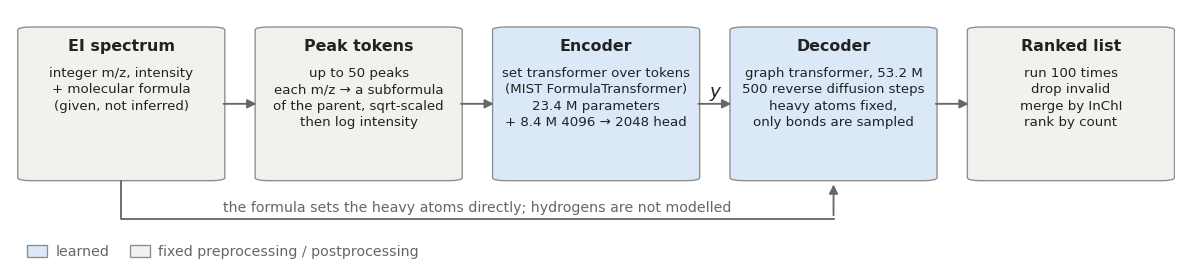

In [3]:
def box(ax, x, y, w, h, title, body, fill):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.008,rounding_size=0.012',
                                facecolor=fill, edgecolor='0.55', linewidth=0.8))
    ax.text(x + w / 2, y + h - 0.04, title, ha='center', va='top', fontsize=9.5, fontweight='bold', color=INK)
    ax.text(x + w / 2, y + h - 0.15, body, ha='center', va='top', fontsize=8, color=INK, linespacing=1.35)


def arrow(ax, a, b, style='-|>', **kw):
    ax.add_patch(FancyArrowPatch(a, b, arrowstyle=style, mutation_scale=11, color=MUTED, linewidth=1.1, **kw))


fig, ax = plt.subplots(figsize=(12.5, 2.7))
ax.set(xlim=(-0.008, 1.008), ylim=(0, 1))
ax.axis('off')
data_fill, net_fill = '#f1f1ee', '#dbe8f8'
W, H, Y0 = 0.165, 0.60, 0.33
XS = [0.005 + i * (W + 0.0425) for i in range(5)]
stages = [
    (XS[0], 'EI spectrum', 'integer m/z, intensity\n+ molecular formula\n(given, not inferred)', data_fill),
    (XS[1], 'Peak tokens', 'up to 50 peaks\neach m/z → a subformula\nof the parent, sqrt-scaled\nthen log intensity', data_fill),
    (XS[2], 'Encoder', 'set transformer over tokens\n(MIST FormulaTransformer)\n23.4 M parameters\n+ 8.4 M 4096 → 2048 head', net_fill),
    (XS[3], 'Decoder', 'graph transformer, 53.2 M\n500 reverse diffusion steps\nheavy atoms fixed,\nonly bonds are sampled', net_fill),
    (XS[4], 'Ranked list', 'run 100 times\ndrop invalid\nmerge by InChI\nrank by count', data_fill),
]
for x, title, body, fill in stages:
    box(ax, x, Y0, W, H, title, body, fill)
for (x, *_), (x2, *_) in zip(stages, stages[1:]):
    arrow(ax, (x + W + 0.004, Y0 + H / 2), (x2 - 0.004, Y0 + H / 2))
ax.text(XS[2] + W + 0.0212, Y0 + H / 2 + 0.03, 'y', ha='center', fontsize=11, style='italic', color=INK)
# The formula reaches the decoder directly, as the atom set of the graph
_x0, _x3 = XS[0] + W / 2, XS[3] + W / 2
ax.plot([_x0, _x0, _x3], [Y0 - 0.01, 0.17, 0.17], color=MUTED, linewidth=1.1)
arrow(ax, (_x3, 0.17), (_x3, Y0 - 0.01))
ax.text((_x0 + _x3) / 2, 0.20, 'the formula sets the heavy atoms directly; hydrogens are not modelled', ha='center',
        fontsize=8.5, color=MUTED)
ax.add_patch(plt.Rectangle((0.005, 0.015), 0.018, 0.05, facecolor=net_fill, edgecolor='0.55', linewidth=0.8))
ax.text(0.03, 0.04, 'learned', va='center', fontsize=8.5, color=MUTED)
ax.add_patch(plt.Rectangle((0.095, 0.015), 0.018, 0.05, facecolor=data_fill, edgecolor='0.55', linewidth=0.8))
ax.text(0.12, 0.04, 'fixed preprocessing / postprocessing', va='center', fontsize=8.5, color=MUTED)
plt.show()

Components of the checkpoint (`exp4_tms_wdec`):

| Stage | Details |
|---|---|
| **Peak tokens** | Up to 50 most intense peaks. Each m/z is mapped to the subformula of the parent with the nearest exact mass. Intensity is scaled as sqrt(I/I_max), then log(x + 1e-5). A zero-intensity CLS token is added. |
| **Encoder** | MIST `FormulaTransformer` in `SpectraEncoderGrowing`: 2 attention layers, 8 heads, pairwise features between tokens, hidden size 512, cosine positional embedding of formula counts, 4 refinement layers giving a 4096-d output. |
| **Merge** | `downproject_4096`: a single linear layer from 4096 to 2048 dimensions. The result is **y**, which is constant throughout a sampling run. |
| **Decoder** | DiGress-style graph transformer: 5 layers, 8 heads, node/edge/global widths 256/64/1024. y enters through the global channel and modulates node and edge updates FiLM-style. Extra features: cycle counts and spectral features at each step. |
| **Diffusion** | Discrete, over 5 bond classes (none, single, double, triple, aromatic). 500 steps, cosine schedule, marginal limit distribution, x0 prediction. Atoms are not diffused. |
| **Postprocessing** | Build the molecule from the sampled graph, sanitise, keep single-fragment valid molecules, merge by InChI, rank by count. |

**Training.** 100 epochs, AdamW, learning rate 1.4e-4, batch size 64, on 454k simulated spectra. The encoder is pretrained alone to predict Morgan fingerprints (radius 2, 2048 bits) with binary cross-entropy. The decoder is pretrained separately. In end-to-end training, both are fine-tuned on cross-entropy over the clean bond classes; the fingerprint loss is switched off (`lambda_train = [1, 1, 0]`), which matters in §4.

**Two consequences for interpreting results.** The formula fixes the heavy atoms, so the model chooses connectivity only. Hydrogens are implicit, filled in from valence, so a candidate can have the right heavy atoms and the wrong H count. Candidates also carry no stereochemistry, so we compare on 2D structure.


## 2. What the model learned from

All spectra here are simulated: NEIMS predicts a spectrum for each structure. The training set combines GECKO-A oxidation products with an augmentation set, with TMS derivatives generated in silico. Molecules in the held-out test sets are removed from training and validation by the first InChIKey block (`data_processing/build_guarded_splits.py`). The Yee library is not part of that guard, so some of its compounds do appear in training; §7 checks whether that matters.


instrument values across all splits: ['simulated']


split,test,train,val
dataset,,,
ferraz-caetano_tms_neims,2293,0,0
gecko_tms_neims,0,171504,5120
kruger-confined_tms_neims,778,0,0
li_tms_neims,1331,0,0
mixed_augment_tms_neims,0,282227,5120
wang_tms_neims,3134,0,0


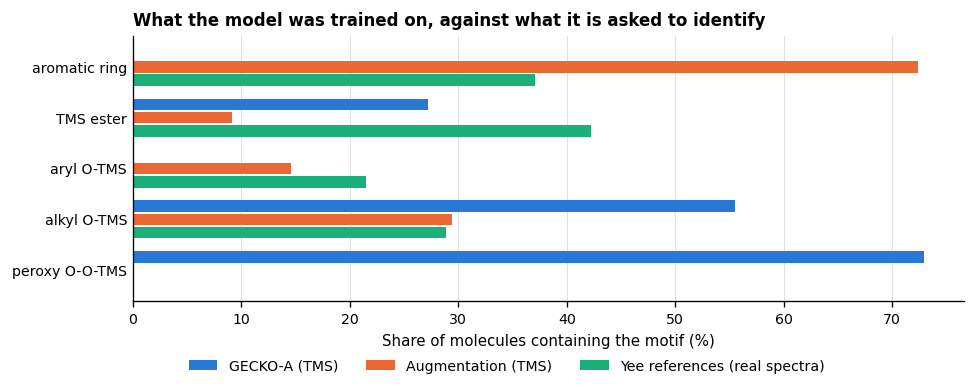

median heavy atoms: {'GECKO-A (TMS)': 27.0, 'Augmentation (TMS)': 30.0, 'Yee references (real spectra)': 19.0}


In [4]:
# Which spectra the model learned from. Reads the 80 MB labels file; takes a few seconds.
train_labels = pd.read_csv(f'{TRAIN_DIR}/labels.tsv', sep='\t',
                           usecols=['dataset', 'spec', 'smiles', 'inchikey', 'instrument'])
train_split = pd.read_csv(f'{TRAIN_DIR}/split_random_guarded.tsv', sep='\t').rename(columns={'name': 'spec'})
train_labels = train_labels.merge(train_split, on='spec')

print('instrument values across all splits:', train_labels['instrument'].unique().tolist())
composition = train_labels.groupby(['dataset', 'split']).size().unstack(fill_value=0)
display(composition)

MOTIFS = {'aromatic ring': 'a', 'TMS ester': 'C(=O)O[Si](C)(C)C', 'aryl O-TMS': 'c-O[Si](C)(C)C',
          'alkyl O-TMS': '[CX4]O[Si](C)(C)C', 'peroxy O-O-TMS': 'OO[Si](C)(C)C'}
MOTIF_Q = {k: Chem.MolFromSmarts(v) for k, v in MOTIFS.items()}


def motif_rates(smiles):
    mols = [m for m in map(Chem.MolFromSmiles, smiles) if m is not None]
    return {k: np.mean([m.HasSubstructMatch(q) for m in mols]) for k, q in MOTIF_Q.items()}, mols


rate_rows, heavy = {}, {}
_train = train_labels[train_labels['split'] == 'train']
for ds, disp in (('gecko_tms_neims', 'GECKO-A (TMS)'), ('mixed_augment_tms_neims', 'Augmentation (TMS)')):
    sample = _train[_train['dataset'] == ds].sample(4000, random_state=0)['smiles']
    rate_rows[disp], _m = motif_rates(sample)
    heavy[disp] = np.median([m.GetNumHeavyAtoms() for m in _m])
ref_smiles = [Chem.MolToSmiles(Chem.MolFromInchi(i)) for i in refs['inchi']]
rate_rows['Yee references (real spectra)'], _m = motif_rates(ref_smiles)
heavy['Yee references (real spectra)'] = np.median([m.GetNumHeavyAtoms() for m in _m])
motif_table = pd.DataFrame(rate_rows)

fig, ax = plt.subplots(figsize=(8.2, 3.4))
ypos = np.arange(len(motif_table))
for i, (col, color) in enumerate(zip(motif_table.columns, (C1, C2, C3))):
    ax.barh(ypos + (i - 1) * 0.26, motif_table[col] * 100, height=0.23, color=color, label=col)
ax.set_yticks(ypos, motif_table.index)
ax.invert_yaxis()
ax.set_xlabel('Share of molecules containing the motif (%)')
ax.set_title('What the model was trained on, against what it is asked to identify')
ax.grid(axis='x', **GRID_KW)
ax.tick_params(axis='y', length=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.45, -0.17), ncol=3)
plt.tight_layout()
plt.show()
print('median heavy atoms:', {k: float(v) for k, v in heavy.items()})

The training chemistry differs from the target chemistry, and that explains some later results, though not all of them:

- **Aromatics** are nearly absent from GECKO-A (0.1%) but common in the augmentation set (72%).
- **O-O-TMS** groups are in 73% of GECKO-A molecules and in none of the references. They reappear as artefacts in 13% of rank-1 candidates (§9).
- **TMS esters** are in 27% of GECKO-A molecules and 42% of the references. Absence from training is therefore not why they are missed (§9).
- **Size.** The median training molecule has 27–30 heavy atoms, the median reference 19.


## 3. What the encoder reads

Our worked example is a pair of isomers: the bis-TMS ethers of catechol and hydroquinone. Their spectra differ strongly in the base peak, m/z 73 against m/z 239 ([M-CH3]+), and the model is given the same atoms for both.

A coloured stick reaches the encoder. The limit of 50 peaks removes grey ones. Both spectra also have weak peaks above M+. that are outside this plot.


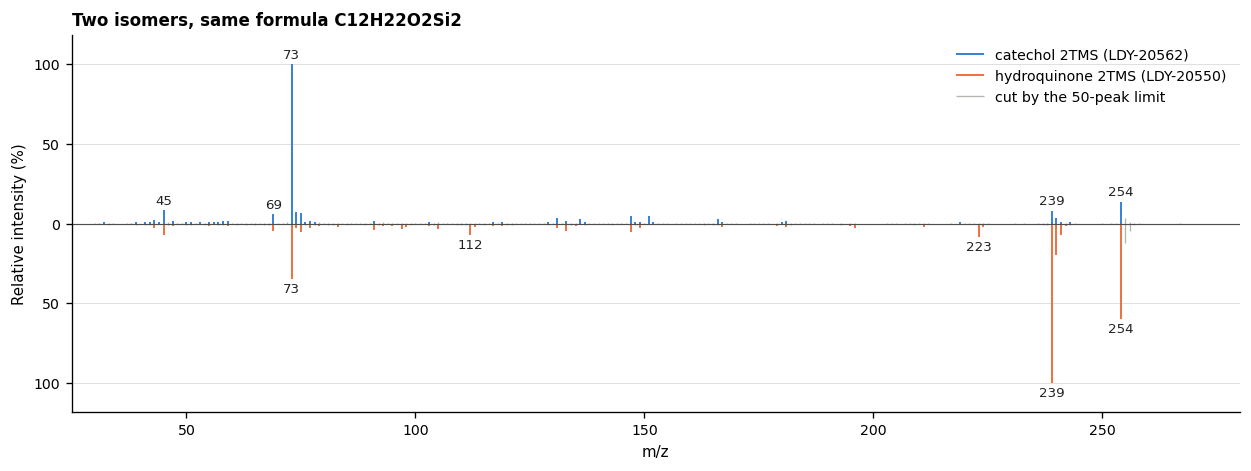

In [5]:
def peak_table(uid):
    """What the encoder receives for one spectrum: one row per token, in token order, with its pooling weight."""
    o = subforms[uid]['output_tbl']
    t = pd.DataFrame({'mz': np.array(o['mz'], dtype=int), 'token': o['formula'],
                      'token_mass': o['mono_mass'], 'scaled_inten': o['ms2_inten']})
    # FormulaTransformer._pool_out, set_pooling='intensity' on inten_transform='log' values. The zero-intensity
    # CLS token sits in the same sum: log(1e-5) is its value.
    log_i = np.r_[np.log(t['scaled_inten'].to_numpy() + 1e-5), np.log(1e-5)]
    t['pool_weight'] = (log_i / log_i.sum())[:-1]
    return t


def raw_spectrum(uid):
    s = np.asarray(spec_df.loc[uid, 'spec'], dtype=float)
    return s[:, 0], s[:, 1] / s[:, 1].max()


def mirror_plot(uid_a, uid_b, label_a, label_b, n_label=7, xmax=280):
    """Head-to-tail spectrum. Coloured sticks reach the encoder; grey ones are cut by the 50-peak limit."""
    fig, ax = plt.subplots(figsize=(10.5, 4.0))
    for uid, sign, color, label in ((uid_a, 1, C1, label_a), (uid_b, -1, C2, label_b)):
        mz, inten = raw_spectrum(uid)
        kept = np.isin(mz, peak_table(uid)['mz'])
        ax.vlines(mz[~kept], 0, sign * inten[~kept] * 100, color=NEUTRAL, linewidth=0.8)
        ax.vlines(mz[kept], 0, sign * inten[kept] * 100, color=color, linewidth=1.1, label=label)
        labelled = []
        for i in np.argsort(-inten)[:n_label]:
            if all(abs(mz[i] - m) >= 4 for m in labelled):   # 74 and 75 sit under the label of 73
                labelled.append(mz[i])
                ax.text(mz[i], sign * (inten[i] * 100 + 2), f'{mz[i]:.0f}', ha='center',
                        va='bottom' if sign > 0 else 'top', fontsize=8, color=INK)
    ax.axhline(0, color='0.3', linewidth=0.7)
    ax.vlines([], 0, 0, color=NEUTRAL, linewidth=0.8, label='cut by the 50-peak limit')
    ax.set_ylim(-118, 118)
    ax.set_xlim(25, xmax)
    ax.set_yticks([-100, -50, 0, 50, 100], [100, 50, 0, 50, 100])
    ax.set_xlabel('m/z')
    ax.set_ylabel('Relative intensity (%)')
    ax.grid(axis='y', **GRID_KW)
    ax.legend(loc='upper right', ncol=1, title=None)
    return fig, ax


fig, ax = mirror_plot(CATECHOL, HYDROQUINONE, 'catechol 2TMS (LDY-20562)', 'hydroquinone 2TMS (LDY-20550)')
ax.set_title('Two isomers, same formula C12H22O2Si2')
plt.tight_layout()
plt.show()

### Peak tokens are not ion assignments

Each peak becomes a token that holds a subformula of the parent. At unit mass the pipeline compares the integer m/z with exact masses of the possible subformulas and takes the nearest. A real ion such as C3H9Si+ has a mass defect of +0.047. A hydrogen-poor formula sits closer to the integer, so it wins. The table compares what a spectroscopist would write with what the encoder receives for the catechol spectrum.


In [6]:
MONO = {'C': 12.0, 'H': 1.00782503, 'O': 15.99491462, 'Si': 27.97692653, 'N': 14.0030740}


def mono_mass(formula):
    return sum(MONO[e] * (int(n) if n else 1) for e, n in re.findall(r'([A-Z][a-z]?)(\d*)', formula))


# The ions a spectroscopist would write for these peaks, against the token the pipeline assigned.
DIAGNOSTIC = {73: ('C3H9Si', 'trimethylsilyl cation'), 75: ('C2H7OSi', 'dimethylsilanol ion'),
              147: ('C5H15OSi2', 'pentamethyldisiloxanyl ion'), 239: ('C11H19O2Si2', '[M - CH3]+'),
              254: ('C12H22O2Si2', 'M+.')}
t = peak_table(CATECHOL).set_index('mz')
display(pd.DataFrame([{'m/z': mz, 'expected ion': ion, 'expected formula': f, 'expected mass': mono_mass(f),
                       'assigned token': t.loc[mz, 'token'], 'token mass': t.loc[mz, 'token_mass'],
                       'scaled intensity': t.loc[mz, 'scaled_inten'], 'pooling weight': t.loc[mz, 'pool_weight']}
                      for mz, (f, ion) in DIAGNOSTIC.items()]).style.hide(axis='index').format(precision=3))

# Across the whole library
tok73 = {True: Counter(), False: Counter()}
n_raw, n_kept, inten_kept = [], [], []
for u in names:
    o = subforms[u]['output_tbl']
    mz, inten = raw_spectrum(u)
    n_raw.append(len(mz))
    n_kept.append(len(o['mz']))
    inten_kept.append(inten[np.isin(mz, o['mz'])].sum() / inten.sum())
    if 73.0 in o['mz']:
        tok73['N' in subforms[u]['cand_form']][o['formula'][o['mz'].index(73.0)]] += 1
print(f'peaks per spectrum: median {np.median(n_raw):.0f} measured -> {np.median(n_kept):.0f} kept; '
      f'kept peaks carry a median {np.median(inten_kept):.0%} of total ion intensity (min {np.min(inten_kept):.0%})')
print('token given to m/z 73 when the parent has no N:', tok73[False].most_common(3))
print('token given to m/z 73 when the parent has N:   ', tok73[True].most_common(4))

m/z,expected ion,expected formula,expected mass,assigned token,token mass,scaled intensity,pooling weight
73,trimethylsilyl cation,C3H9Si,73.047,C6H,73.007,1.000,-0.000
75,dimethylsilanol ion,C2H7OSi,75.027,CH3O2Si,74.990,0.255,0.013
147,pentamethyldisiloxanyl ion,C5H15OSi2,147.066,C7H7Si2,147.008,0.212,0.015
239,[M - CH3]+,C11H19O2Si2,239.092,C12H7O2Si2,238.998,0.285,0.012
254,M+.,C12H22O2Si2,254.116,C12H22O2Si2,254.115,0.368,0.009


peaks per spectrum: median 214 measured -> 50 kept; kept peaks carry a median 85% of total ion intensity (min 5%)
token given to m/z 73 when the parent has no N: [('C6H', 614)]
token given to m/z 73 when the parent has N:    [('CH3NOSi', 33), ('C6H', 13), ('C2HO3', 4), ('CHN2O2', 1)]


The trimethylsilyl cation, the most characteristic ion of this chemistry, reaches the model as `C6H` in 627 of the 665 spectra that have the peak. Of the five ions in the table, only M+. gets its true formula, because it is the parent itself.

The rule depends only on m/z and the parent formula, so the token behaves as a consistent code for m/z, not as chemistry. That is why the model can still learn from it. We expect training spectra to follow the same rule; a partial check of 571 training entries, all with nitrogen-bearing parents, showed m/z 73 mapped mostly to `CH3NOSi`, which matches the rule. We did not check parents without nitrogen. Two consequences:

- The model is not told what any fragment is. A corrected assignment for known TMS ions is a possible improvement, not tested here.
- The same m/z can get a different token depending on the parent.

**Peak limit.** The library has a median of 214 peaks per spectrum, of which 50 are kept. That keeps a median of 85% of the ion intensity, and in the worst case only 5%.

**Pooling.** The `pooling weight` column looks wrong and probably is. The config combines `set_pooling: intensity` with `inten_transform: log`, so weights are proportional to the log of a value at or below 1. The base peak's log is about 0, so its pooling weight is about 0, and the weakest peaks get the largest weights. In the catechol spectrum, m/z 73 has weight about 0, and the CLS token has 10.8%. Intensity still reaches the network as an input feature and through attention, and the next section shows that strong peaks do matter. The checkpoint was trained this way, so nothing here is a mismatch at inference, but this looks unintended and is worth testing.


## 4. What the encoder produces

y is a 2048-d vector, and it was pretrained to predict a Morgan fingerprint. Is it still one after end-to-end training, where nothing supervises it directly?


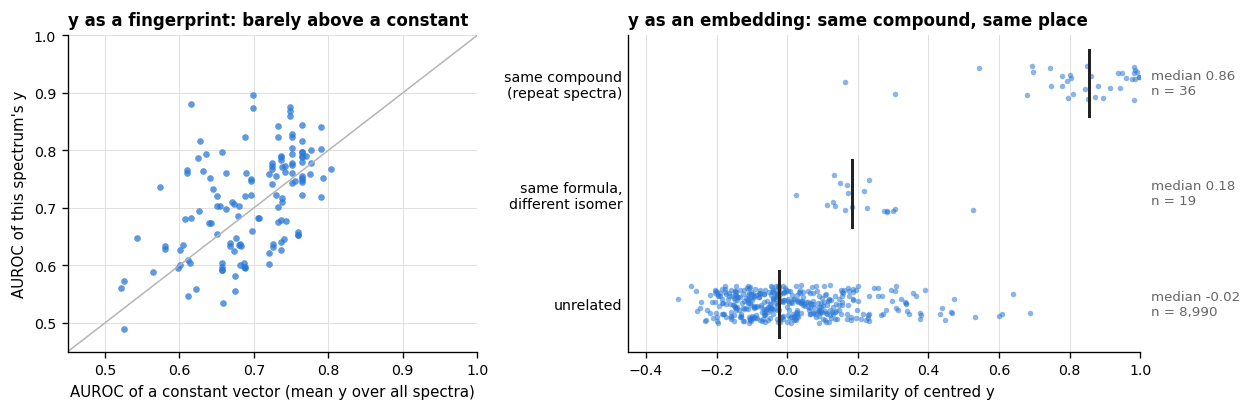

mean per-spectrum AUROC: y 0.711, constant 0.695; y wins on 58% of spectra


In [7]:
# y against the true Morgan bits, and against a vector that knows nothing about the spectrum
auc_y, auc_const, labelled = [], [], []
for uid, r in refs.iterrows():
    bits = np.zeros(MORGAN_NBITS, dtype=int)
    DataStructs.ConvertToNumpyArray(morgan(Chem.MolFromInchi(r['inchi'])), bits)
    auc_y.append(roc_auc_score(bits, y_of[uid]))
    auc_const.append(roc_auc_score(bits, Y_MEAN))
auc_y, auc_const = np.array(auc_y), np.array(auc_const)

# Do repeat measurements of one compound land together? Centred, because all y share a large common component.
Z = {u: (y_of[u] - Y_MEAN) / np.linalg.norm(y_of[u] - Y_MEAN) for u in refs.index}
smiles_2d = {u: Chem.MolToSmiles(Chem.MolFromInchi(r['inchi']), isomericSmiles=False) for u, r in refs.iterrows()}
pairs = {'same compound\n(repeat spectra)': [], 'same formula,\ndifferent isomer': [], 'unrelated': []}
for a, b in combinations(refs.index, 2):
    sim = float(Z[a] @ Z[b])
    if smiles_2d[a] == smiles_2d[b]:
        pairs['same compound\n(repeat spectra)'].append(sim)
    elif refs.loc[a, 'formula'] == refs.loc[b, 'formula']:
        pairs['same formula,\ndifferent isomer'].append(sim)
    else:
        pairs['unrelated'].append(sim)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.5), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
ax.plot([0.45, 1], [0.45, 1], color=NEUTRAL, linewidth=0.9)
ax.scatter(auc_const, auc_y, s=16, color=C1, alpha=0.75, linewidths=0)
ax.set(xlim=(0.45, 1), ylim=(0.45, 1), xlabel='AUROC of a constant vector (mean y over all spectra)',
       ylabel='AUROC of this spectrum\'s y')
ax.set_title('y as a fingerprint: barely above a constant')
ax.grid(**GRID_KW)

ax = axes[1]
rng = np.random.default_rng(0)
for i, (k, v) in enumerate(pairs.items()):
    v = np.array(v)
    show_v = rng.choice(v, min(len(v), 400), replace=False)
    ax.scatter(show_v, i + rng.uniform(-0.17, 0.17, len(show_v)), s=11, color=C1, alpha=0.55, linewidths=0)
    ax.plot([np.median(v)] * 2, [i - 0.3, i + 0.3], color=INK, linewidth=1.8)
    ax.text(1.03, i, f'median {np.median(v):.2f}\nn = {len(v):,}', va='center', fontsize=8, color=MUTED)
ax.set_yticks(range(len(pairs)), list(pairs))
ax.invert_yaxis()
ax.set(xlim=(-0.45, 1.0), xlabel='Cosine similarity of centred y')
ax.set_title('y as an embedding: same compound, same place')
ax.grid(axis='x', **GRID_KW)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()
print(f'mean per-spectrum AUROC: y {auc_y.mean():.3f}, constant {auc_const.mean():.3f}; '
      f'y wins on {np.mean(auc_y > auc_const):.0%} of spectra')

**Left:** no. Scored against the true Morgan bits, y has a mean per-spectrum AUROC of 0.71, against 0.70 for a constant vector that ignores the spectrum. Most of that score comes from common bits being common.

**Right:** y is still informative as an embedding. After removing the mean, repeat spectra of one compound have a median cosine of 0.86, isomers 0.18, and unrelated compounds about 0. Many repeats come from different campaigns, so y is fairly stable against real-world variation.

So y is best read as a learned conditioning vector. Ranking candidates by cos(y, candidate fingerprint), as if y were a fingerprint, does worse than ranking by count (§8).

### Which peaks move y?

Delete each peak in turn, re-run the encoder and measure how far y moves. This takes seconds, and it uses the real checkpoint: the rebuilt tokens reproduce the y stored by the cluster run.


rebuilt tokens reproduce the stored y of the run to within 7.5e-07


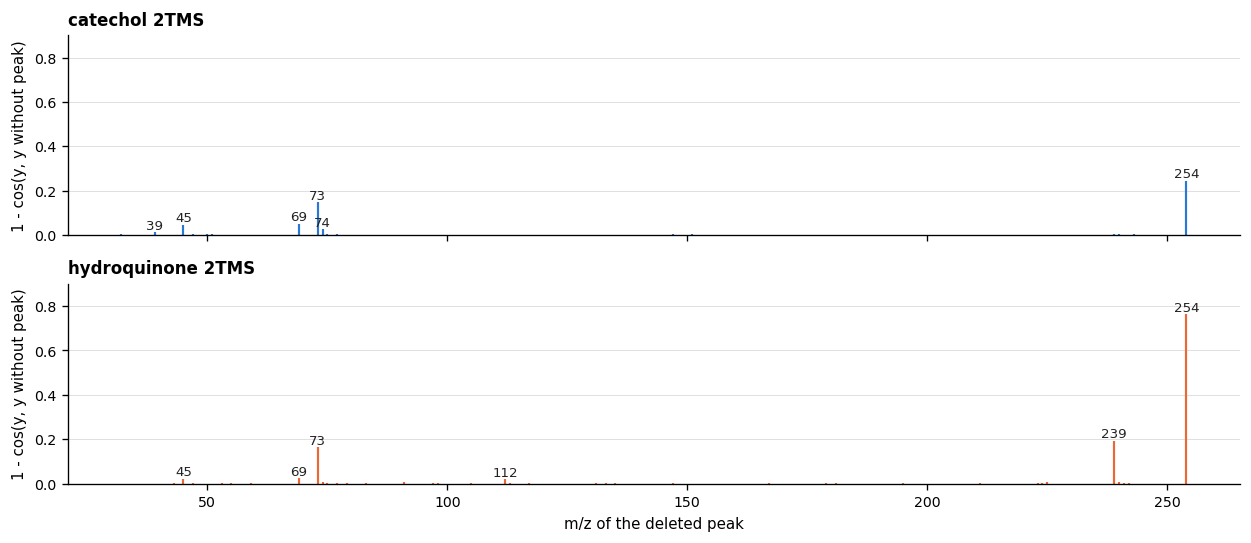

catechol: top peaks by influence [254, 73, 69, 45, 74, 39], by intensity [73, 254, 45, 239, 74, 75]; Spearman(influence, intensity) = 0.60
hydroquinone: top peaks by influence [254, 239, 73, 69, 45, 112], by intensity [239, 254, 73, 240, 223, 45]; Spearman(influence, intensity) = 0.60


In [8]:
_live = {}


def live():
    """Build the model from the checkpoint once, on first use. Nothing above this needs it."""
    if _live:
        return _live
    from hydra import compose, initialize_config_dir
    from hydra.core.global_hydra import GlobalHydra
    from src.analysis.visualization import MolecularVisualization
    from src.datasets.inference_dataset import InferenceDataModule, InferenceDatasetInfos
    from src.diffusion.extra_features import ExtraFeatures
    from src.diffusion.extra_features_molecular import ExtraMolecularFeatures
    from src.diffusion_model_spec2mol import Spec2MolDenoisingDiffusion
    from src.metrics.molecular_metrics_discrete import TrainMolecularMetricsDiscrete

    torch.set_num_threads(LIVE_THREADS)
    ck = torch.load(CKPT, map_location='cpu', weights_only=False, mmap=True)
    model_cfg = ck['hyper_parameters']['cfg']
    cwd = os.getcwd()
    os.chdir(REPO)      # configs/dataset/yee.yaml paths are repo-relative
    try:
        GlobalHydra.instance().clear()
        with initialize_config_dir(version_base='1.3', config_dir=os.path.join(REPO, 'configs')):
            cfg = compose(config_name='config_inference', overrides=[
                'dataset.stats_dir=' + model_cfg.dataset.stats_dir.replace('../../../', ''),
                'train.eval_batch_size=1', 'train.num_workers=0'])
        dm = InferenceDataModule(cfg)
        infos = InferenceDatasetInfos(dm, cfg)
        domain = ExtraMolecularFeatures(dataset_infos=infos)
        extra = ExtraFeatures(cfg.model.extra_features, dataset_info=infos)
        infos.compute_input_output_dims(datamodule=dm, extra_features=extra, domain_features=domain)
        model = Spec2MolDenoisingDiffusion(
            model_cfg, dataset_infos=infos, train_metrics=TrainMolecularMetricsDiscrete(infos),
            visualization_tools=MolecularVisualization(cfg.dataset.remove_h, dataset_infos=infos),
            extra_features=extra, domain_features=domain, load_pretrained_weights=False)
        model.load_state_dict(ck['state_dict'], strict=True)
    finally:
        os.chdir(cwd)
    del ck
    ds = dm.test_dataset
    _live.update(model=model.eval(), ds=ds, collate=dm.test_dataloader().collate_fn,
                 index={n: i for i, n in enumerate(ds.get_spectra_names())})
    return _live


def spectrum_batch(uid):
    L = live()
    return L['collate']([L['ds'][L['index'][uid]]])


@torch.no_grad()
def encode(batch):
    """Spectrum batch -> y, as predict_fingerprint in src/inference.py does for merge=downproject_4096."""
    m = live()['model']
    return m.merge_function(m.encoder(batch)[0])


def batch_from_tokens(base, form_vec, scaled_inten):
    """A one-spectrum batch with these peaks. form_vec and scaled_inten exclude the trailing CLS token."""
    n = len(scaled_inten)
    return {**base,
            'types': torch.tensor([[0] * n + [3]]),
            'form_vec': torch.cat([form_vec, torch.zeros(1, form_vec.shape[1])])[None],
            'ion_vec': torch.full((1, n + 1), float(base['ion_vec'][0, 0])),
            'intens': torch.log(torch.cat([scaled_inten, torch.zeros(1)]) + 1e-5)[None].float(),
            'num_peaks': torch.tensor([n + 1])}


def tokens_of(uid):
    b = spectrum_batch(uid)
    n = int(b['num_peaks'][0]) - 1      # the last token is CLS
    return b, b['form_vec'][0, :n], torch.exp(b['intens'][0, :n]) - 1e-5


def occlusion(uid):
    """Delete each peak in turn and measure how far y moves."""
    b, forms, inten = tokens_of(uid)
    y0 = encode(batch_from_tokens(b, forms, inten))[0].numpy()
    z0 = y0 - Y_MEAN
    rows = []
    for i in range(len(inten)):
        keep = torch.arange(len(inten)) != i
        z = encode(batch_from_tokens(b, forms[keep], inten[keep]))[0].numpy() - Y_MEAN
        rows.append(1 - float(z @ z0 / (np.linalg.norm(z) * np.linalg.norm(z0))))
    t = peak_table(uid).assign(moved=rows)
    return {'table': t, 'y_error': float(np.abs(y0 - y_of[uid]).max())}


occ = {u: cached(f'occlusion_{u}', lambda u=u: occlusion(u)) for u in (CATECHOL, HYDROQUINONE)}
print('rebuilt tokens reproduce the stored y of the run to within',
      f'{max(o["y_error"] for o in occ.values()):.1e}')

fig, axes = plt.subplots(2, 1, figsize=(10.5, 4.6), sharex=True, sharey=True)
for ax, u, color, title in ((axes[0], CATECHOL, C1, 'catechol 2TMS'), (axes[1], HYDROQUINONE, C2, 'hydroquinone 2TMS')):
    t = occ[u]['table']
    ax.vlines(t['mz'], 0, t['moved'], color=color, linewidth=1.3)
    for _, r in t.nlargest(6, 'moved').iterrows():
        ax.text(r['mz'], r['moved'], f"{r['mz']:.0f}", ha='center', va='bottom', fontsize=8, color=INK)
    ax.set_ylim(0, 0.9)
    ax.set_ylabel('1 - cos(y, y without peak)')
    ax.set_title(title)
    ax.grid(axis='y', **GRID_KW)
axes[1].set_xlabel('m/z of the deleted peak')
plt.tight_layout()
plt.show()
for u, name in ((CATECHOL, 'catechol'), (HYDROQUINONE, 'hydroquinone')):
    t = occ[u]['table']
    print(f"{name}: top peaks by influence {t.nlargest(6, 'moved')['mz'].tolist()}, "
          f"by intensity {t.nlargest(6, 'scaled_inten')['mz'].tolist()}; "
          f"Spearman(influence, intensity) = {t['moved'].corr(t['scaled_inten'], method='spearman'):.2f}")

- **M+. has the largest effect in both spectra**, and more for hydroquinone (0.76) than catechol (0.25).
- **The next most influential peaks are those that differ most between the isomers**: m/z 73 for catechol, and m/z 239 and 73 for hydroquinone. Neighbouring peaks also move y a little, such as 69 and 45.
- **Most peaks do almost nothing.** Deleting any of 41 of the 47 catechol peaks, or 39 of the 45 hydroquinone peaks, moves y by less than 0.01. That includes m/z 147, a classic marker of molecules with two or more TMS groups, which is about 5% of the base peak in the catechol spectrum but moves y by only 0.006.
- **Influence is not intensity.** Rank correlation with intensity is 0.60. Also, the base peak has about zero pooling weight, and it still matters, so that influence must come through attention.

Two limits on this reading. Deleting one peak at a time misses redundancy between peaks, so a small effect does not prove that a peak is unused. And this measures movement of y, not change in the sampled structures.


## 5. Diffusion over bonds

The state is the bond matrix: one of 5 classes per atom pair, with atoms fixed. The forward process moves each pair towards the training marginals, with

$q(E_t \mid E_0) = \bar\alpha_t\, E_0 + (1 - \bar\alpha_t)\, m$

where $m$ is the marginal distribution of bond classes. Since 95% of atom pairs have no bond, noise mostly removes bonds and adds a few at random. This makes the limit distribution sparse, like a molecule, rather than uniform, as in DiGress with marginal transitions.


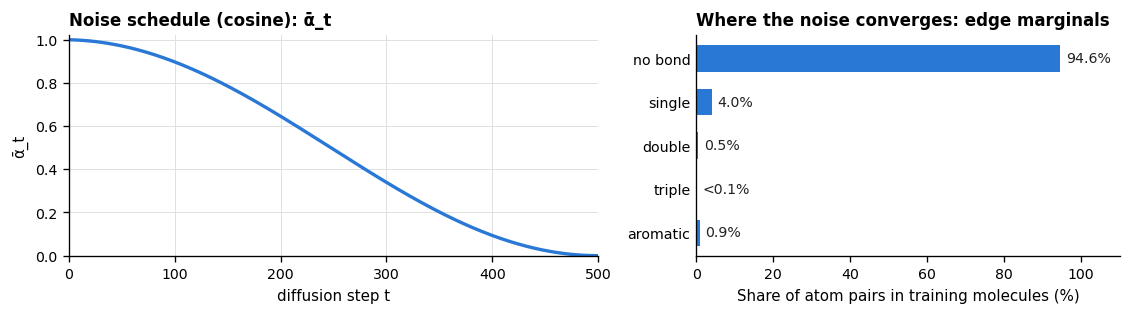

In [9]:
from src.diffusion.noise_schedule import MarginalUniformTransition, PredefinedNoiseScheduleDiscrete

T = 500
BOND_NAMES = ['no bond', 'single', 'double', 'triple', 'aromatic']
schedule = PredefinedNoiseScheduleDiscrete('cosine', T)
edge_marginals = torch.tensor(np.loadtxt(f'{TRAIN_DIR}/stats/edge_types.txt')).float()
edge_marginals = edge_marginals / edge_marginals.sum()
atom_marginals = torch.tensor(np.loadtxt(f'{TRAIN_DIR}/stats/atom_types.txt')).float()
transition = MarginalUniformTransition(atom_marginals / atom_marginals.sum(), edge_marginals, y_classes=0)
alpha_bar = schedule.get_alpha_bar(t_int=torch.arange(T + 1)).numpy()

fig, axes = plt.subplots(1, 2, figsize=(9.5, 2.7), gridspec_kw={'width_ratios': [1.25, 1]})
axes[0].plot(np.arange(T + 1), alpha_bar, color=C1, linewidth=2)
axes[0].set(xlabel='diffusion step t', ylabel='ᾱ_t', xlim=(0, T), ylim=(0, 1.02))
axes[0].set_title('Noise schedule (cosine): ᾱ_t')
axes[0].grid(**GRID_KW)
axes[1].barh(BOND_NAMES, edge_marginals.numpy() * 100, color=C1, height=0.6)
for i, v in enumerate(edge_marginals.numpy()):
    axes[1].text(v * 100 + 1.5, i, f'{v:.1%}' if v >= 0.001 else '<0.1%', va='center', fontsize=8.5, color=INK)
axes[1].invert_yaxis()
axes[1].set(xlim=(0, 110), xlabel='Share of atom pairs in training molecules (%)')
axes[1].set_title('Where the noise converges: edge marginals')
axes[1].tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()

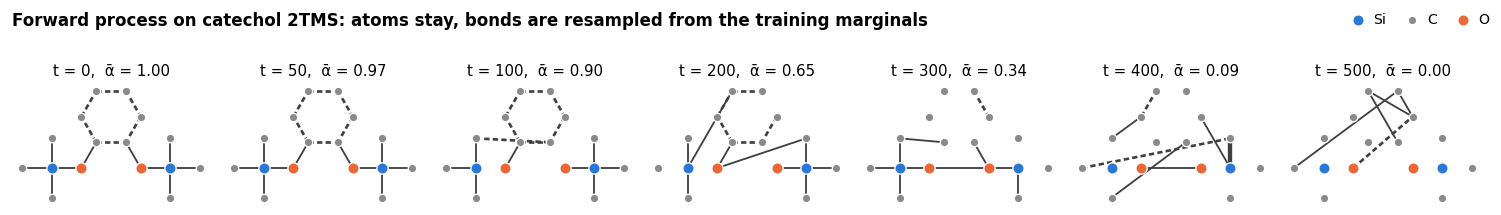

In [10]:
BOND_STYLE = {1: dict(linewidth=1.1, linestyle='-'), 2: dict(linewidth=2.6, linestyle='-'),
              3: dict(linewidth=3.6, linestyle='-'), 4: dict(linewidth=1.6, linestyle=(0, (2, 1.2)))}
ATOM_COLOR = {'C': '#8a8a86', 'O': C2, 'Si': C1}


def draw_graph(ax, symbols, E, pos, title=None):
    """A bond matrix drawn on fixed atom positions, so noise shows as wrong edges rather than a moving layout."""
    n = len(symbols)
    for i in range(n):
        for j in range(i + 1, n):
            if E[i, j] > 0:
                ax.plot(pos[[i, j], 0], pos[[i, j], 1], color='0.25', zorder=1, solid_capstyle='round',
                        **BOND_STYLE[int(E[i, j])])
    for s in set(symbols):
        idx = [i for i, a in enumerate(symbols) if a == s]
        ax.scatter(pos[idx, 0], pos[idx, 1], s=46 if s != 'C' else 26, color=ATOM_COLOR.get(s, C4),
                   edgecolor='white', linewidth=0.8, zorder=2, label=s)
    ax.set_aspect('equal')
    ax.axis('off')
    if title:
        ax.set_title(title, fontsize=9, fontweight='normal', loc='center')


def layout(mol):
    m = Chem.Mol(mol)
    AllChem.Compute2DCoords(m)
    return m.GetConformer().GetPositions()[:, :2]


def bond_matrix(mol):
    E = np.zeros((mol.GetNumAtoms(), mol.GetNumAtoms()), dtype=np.uint8)
    code_of = {Chem.BondType.SINGLE: 1, Chem.BondType.DOUBLE: 2, Chem.BondType.TRIPLE: 3, Chem.BondType.AROMATIC: 4}
    for b in mol.GetBonds():
        E[b.GetBeginAtomIdx(), b.GetEndAtomIdx()] = E[b.GetEndAtomIdx(), b.GetBeginAtomIdx()] = code_of[b.GetBondType()]
    return E


def noised(E0, t, rng):
    """Sample E_t ~ q(E_t | E_0) with the model's own transition matrices, keeping the matrix symmetric."""
    Q = transition.get_Qt_bar(schedule.get_alpha_bar(t_int=torch.tensor([[t]])), 'cpu').E[0].numpy()
    n = len(E0)
    E = np.zeros_like(E0)
    for i in range(n):
        for j in range(i + 1, n):
            p = Q[E0[i, j]]
            E[i, j] = E[j, i] = rng.choice(5, p=p / p.sum())
    return E


cat_mol = Chem.MolFromSmiles(ORTHO)
cat_symbols = [a.GetSymbol() for a in cat_mol.GetAtoms()]
cat_pos, cat_E0 = layout(cat_mol), bond_matrix(cat_mol)
rng = np.random.default_rng(3)
steps = [0, 50, 100, 200, 300, 400, 500]
fig, axes = plt.subplots(1, len(steps), figsize=(12.5, 2.0))
for ax, t in zip(axes, steps):
    draw_graph(ax, cat_symbols, noised(cat_E0, t, rng) if t else cat_E0, cat_pos,
               f't = {t},  ᾱ = {alpha_bar[t]:.2f}')
fig.suptitle('Forward process on catechol 2TMS: atoms stay, bonds are resampled from the training marginals',
             x=0.01, ha='left', fontsize=10, fontweight='bold')
_h, _l = axes[0].get_legend_handles_labels()
fig.legend(_h, _l, loc='upper right', ncol=3, handletextpad=0.1, columnspacing=0.8)
plt.tight_layout()
plt.show()

### Reverse process

Sampling starts from the marginals at t = 500. At each step, the decoder predicts the clean bond classes from the current graph, y and the extra features. The next graph is sampled from the resulting posterior. y does not change along the chain.

This is a new run on one spectrum, with 16 samples, so that the whole path could be stored.


16 samples from the catechol spectrum:
C[Si](C)(C)Oc1ccccc1O[Si](C)(C)C      10
C[Si](C)(C)Oc1cccc(O[Si](C)(C)C)c1     2
C[Si](C)(C)CCc1cc(O[Si](C)(C)C)co1     1
C[Si](C)(C)Oc1ccc(O[Si](C)(C)C)cc1     1
C[SiH](C)COc1ccccc1O[Si](C)(C)C        1
C[Si](C)(C)Oc1ccc2cc1O[Si](C)(C)C2     1


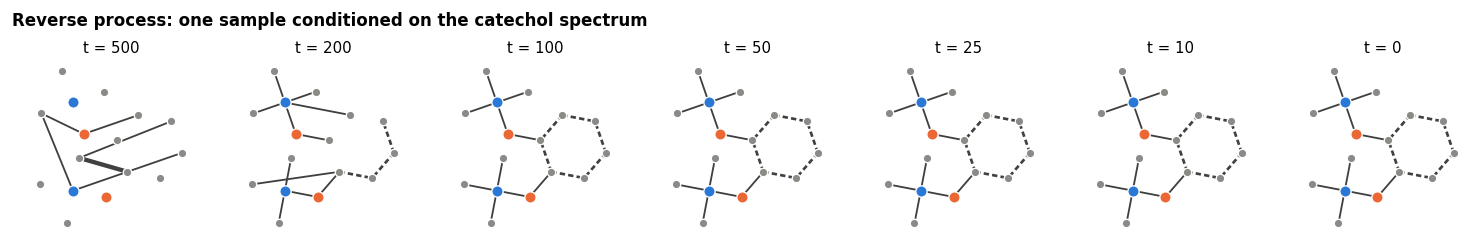

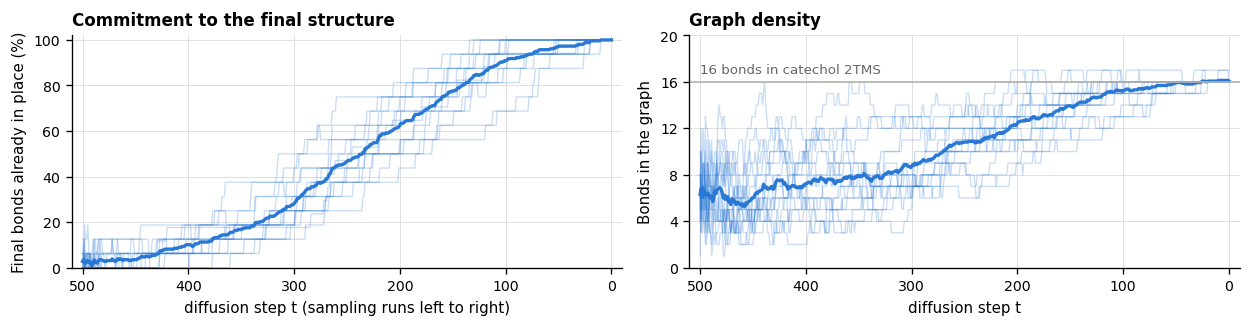

50% of the final bonds in place, on average, by t = 235
75% of the final bonds in place, on average, by t = 160
90% of the final bonds in place, on average, by t = 105
99% of the final bonds in place, on average, by t = 20


In [11]:
@torch.no_grad()
def sample_chain(example, y, n, seed, keep_chain=False):
    """sample_batch from src/diffusion_model_spec2mol.py for n copies of one spectrum, keeping the path if asked."""
    from torch_geometric.data import Batch
    from src import utils as diffms_utils
    from src.diffusion import diffusion_utils

    model = live()['model']
    torch.manual_seed(seed)
    data = Batch.from_data_list([example] * n)
    dense, node_mask = diffms_utils.to_dense(data.x, data.edge_index, data.edge_attr, data.batch)
    z_T = diffusion_utils.sample_discrete_feature_noise(limit_dist=model.limit_dist, node_mask=node_mask)
    X, E, y_batch = dense.X, z_T.E, y.expand(n, -1)
    chain = [E.argmax(-1).numpy().astype(np.uint8)] if keep_chain else None
    for s_int in reversed(range(T)):
        s = s_int * torch.ones((n, 1))
        out, _ = model.sample_p_zs_given_zt(s / T, (s + 1) / T, X, E, y_batch, node_mask)
        E = out.E
        if keep_chain:
            chain.append(E.argmax(-1).numpy().astype(np.uint8))
    nodes, adj = X.argmax(-1), E.argmax(-1)
    smiles = []
    for nd, ad in zip(nodes, adj):
        mol = model.visualization_tools.mol_from_graphs(nd, ad)
        smiles.append(Chem.MolToSmiles(mol) if diffms_utils.is_valid(mol) else None)
    return {'smiles': smiles, 'chain': None if chain is None else np.stack(chain),
            'symbols': [model.dataset_info.atom_decoder[int(i)] for i in nodes[0]]}


def example_of(uid):
    return spectrum_batch(uid)['graph'].get_example(0)


def run_trajectory():
    y = torch.from_numpy(y_of[CATECHOL])[None]
    return sample_chain(example_of(CATECHOL), y, LIVE_BATCH, SEED, keep_chain=True)


traj = cached('trajectory_catechol', run_trajectory)
chain, traj_smiles, symbols = traj['chain'], traj['smiles'], traj['symbols']   # chain: step x sample x n x n; chain[0] is t=T
print(f'{LIVE_BATCH} samples from the catechol spectrum:')
print(pd.Series([s if s else '(invalid)' for s in traj_smiles]).value_counts().to_string())

ortho_canon = Chem.CanonSmiles(ORTHO)
pick = next((i for i, s in enumerate(traj_smiles) if s == ortho_canon),
            next(i for i, s in enumerate(traj_smiles) if s))
final_mol = Chem.MolFromSmiles(traj_smiles[pick])
# Positions come from the final molecule, keyed by node index of the generated graph
final_rw = Chem.RWMol()
for sym in symbols:
    final_rw.AddAtom(Chem.Atom(sym))
for i, j in zip(*np.triu_indices(len(symbols), 1)):
    c = chain[-1, pick, i, j]
    if c:
        final_rw.AddBond(int(i), int(j), {1: Chem.BondType.SINGLE, 2: Chem.BondType.DOUBLE,
                                          3: Chem.BondType.TRIPLE, 4: Chem.BondType.AROMATIC}[int(c)])
gen_mol = final_rw.GetMol()
Chem.SanitizeMol(gen_mol)
gen_pos = layout(gen_mol)

show_t = [500, 200, 100, 50, 25, 10, 0]
fig, axes = plt.subplots(1, len(show_t), figsize=(12.5, 2.0))
for ax, t in zip(axes, show_t):
    draw_graph(ax, symbols, chain[T - t, pick], gen_pos, f't = {t}')
fig.suptitle('Reverse process: one sample conditioned on the catechol spectrum',
             x=0.01, ha='left', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

# When does each sample commit? Share of its final bonds already present, with the final bond type.
iu = np.triu_indices(len(symbols), 1)
pairs_t = chain[:, :, iu[0], iu[1]]         # step x sample x atom pair
final_bonds = pairs_t[-1] > 0
in_place = ((pairs_t == pairs_t[-1]) & final_bonds).sum(-1) / final_bonds.sum(-1) * 100
n_bonds = (pairs_t > 0).sum(-1)
tt = T - np.arange(T + 1)
fig, axes = plt.subplots(1, 2, figsize=(10.5, 2.8))
for s in range(LIVE_BATCH):
    axes[0].plot(tt, in_place[:, s], color=C1, alpha=0.25, linewidth=0.8)
    axes[1].plot(tt, n_bonds[:, s], color=C1, alpha=0.25, linewidth=0.8)
axes[0].plot(tt, in_place.mean(1), color=C1, linewidth=2)
axes[0].set(xlabel='diffusion step t (sampling runs left to right)', ylabel='Final bonds already in place (%)', ylim=(0, 102))
axes[0].set_title('Commitment to the final structure')
axes[1].plot(tt, n_bonds.mean(1), color=C1, linewidth=2)
axes[1].axhline(cat_mol.GetNumBonds(), color=NEUTRAL, linewidth=1)
axes[1].text(T, cat_mol.GetNumBonds() + 0.5, f'{cat_mol.GetNumBonds()} bonds in catechol 2TMS', ha='left',
             va='bottom', fontsize=8, color=MUTED)
axes[1].set(xlabel='diffusion step t', ylabel='Bonds in the graph', ylim=(0, 20))
axes[1].set_title('Graph density')
axes[1].set_yticks(range(0, 21, 4))
for ax in axes:
    ax.set_xlim(T + 10, -10)
    ax.grid(**GRID_KW)
plt.tight_layout()
plt.show()
for lvl in (50, 75, 90, 99):
    print(f'{lvl}% of the final bonds in place, on average, by t = {tt[np.argmax(in_place.mean(1) >= lvl)]}')

The structure forms gradually: on average half of the final bonds are in place by t = 235, and 90% by t = 105. The bond count stays low until late, at about 9 at t = 300, then climbs to the 16 of the molecule. In the sample drawn, the ring and both TMS groups are in place by t = 100, and later steps barely change it.

Ten of 16 samples gave the catechol derivative, in line with the 52 of 100 in the saved run. The rest show the typical alternatives: the other positional isomers, and molecules with Si-C in place of Si-O.

**Why we rank by count.** Sampling draws from an implicit distribution over graphs. The count of a structure estimates its probability, given the spectrum and the formula. With 100 samples, the resolution is 1%, and any structure below that may not appear at all.


## 6. Does the spectrum determine the structure?

The library holds 8 spectra with formula C12H22O2Si2, from 4 campaigns. This is a natural experiment: the atoms are identical, so anything that differs comes from the spectrum. Candidates come from the saved run, and the labels include the base peak and retention index (RI), which the model does not see.


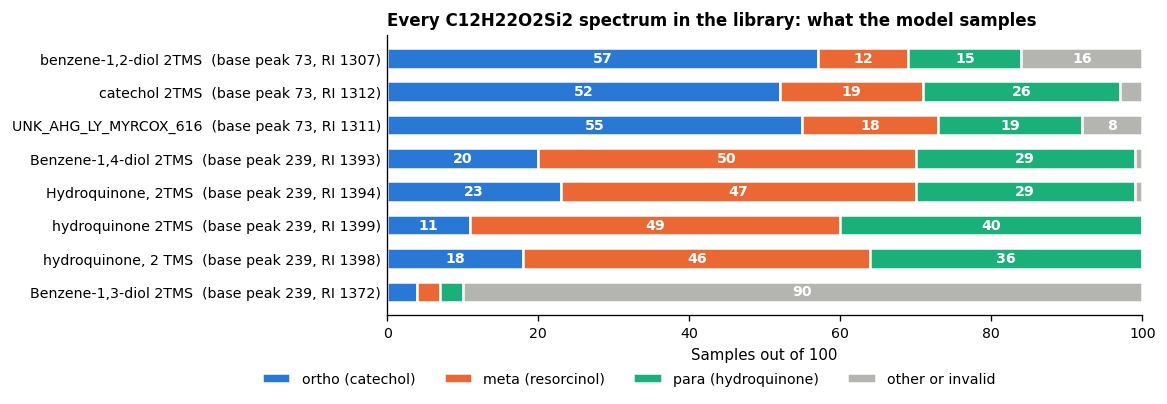

In [12]:
def isomer_shares(uid):
    """Share of the 100 samples per isomer. Everything else, invalid samples included, is 'other'."""
    g = by_uid.get(uid)
    out = {k: (0 if g is None else int(g.loc[g['smiles'] == Chem.CanonSmiles(s), 'count'].sum())) for k, s in ISOMERS.items()}
    out['other or invalid'] = N_SAMPLES - sum(out.values())
    return out


same_formula = labels[labels['formula'] == EXAMPLE_FORMULA]
kind = lambda n: ('catechol' if re.search(r'catechol|1,2-diol', n, re.I) else
                  'hydroquinone' if re.search(r'hydroquinone|1,4-diol', n, re.I) else
                  'resorcinol' if re.search(r'1,3-diol', n, re.I) else 'unnamed')
iso = pd.DataFrame([{'uid': u, 'library name': labels.loc[u, 'compound_name'], 'campaign': labels.loc[u, 'source'],
                     'kind': kind(labels.loc[u, 'compound_name']),
                     'base peak': int(raw_spectrum(u)[0][raw_spectrum(u)[1].argmax()]), 'RI': int(labels.loc[u, 'RI']),
                     **isomer_shares(u)} for u in same_formula.index])
iso['_o'] = iso['kind'].map({'catechol': 0, 'unnamed': 1, 'hydroquinone': 2, 'resorcinol': 3})
iso = iso.sort_values(['_o', 'uid']).drop(columns='_o').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9.8, 3.5))
cats, colors = list(ISOMERS) + ['other or invalid'], [C1, C2, C3, NEUTRAL]
ypos = np.arange(len(iso))
left = np.zeros(len(iso))
for c, col in zip(cats, colors):
    ax.barh(ypos, iso[c], left=left, height=0.62, color=col, edgecolor='white', linewidth=1.5, label=c)
    for y_, l_, v in zip(ypos, left, iso[c]):
        if v >= 8:
            ax.text(l_ + v / 2, y_, f'{v}', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    left += iso[c].to_numpy()
ax.set_yticks(ypos, [f"{r['library name']}  (base peak {r['base peak']}, RI {r['RI']})" for _, r in iso.iterrows()])
ax.invert_yaxis()
ax.set(xlim=(0, 100), xlabel='Samples out of 100')
ax.set_title(f'Every {EXAMPLE_FORMULA} spectrum in the library: what the model samples')
ax.tick_params(axis='y', length=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.32, -0.16), ncol=4)
plt.tight_layout()
plt.show()

catechol 2TMS (LDY-20562)


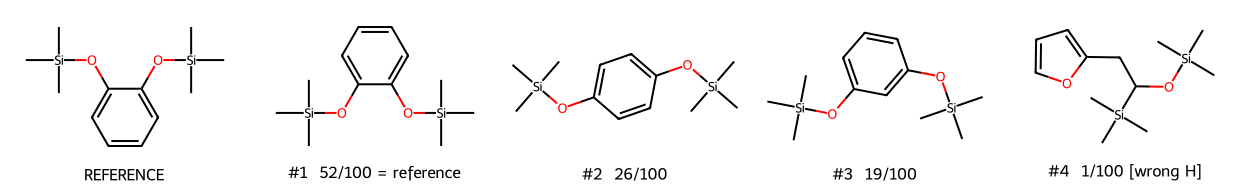

hydroquinone 2TMS (LDY-20550)


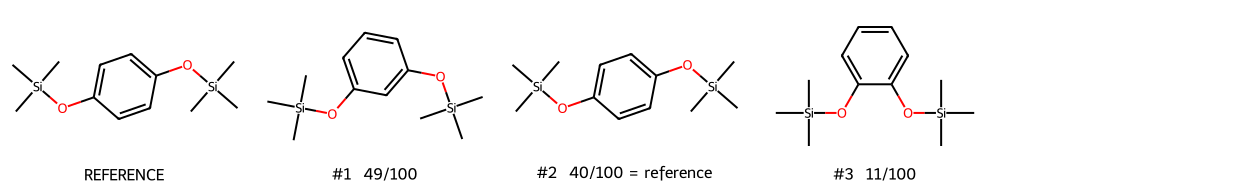

In [13]:
def grid_for(uid, k=8):
    """Top-k candidates of a spectrum, ranked by count; the reference, if known, drawn first."""
    g = by_uid.get(uid)
    mols, legends = [], []
    true_key = None
    if uid in refs.index:
        true_key = key_2d(refs.loc[uid, 'inchi'])
        mols.append(Chem.MolFromInchi(refs.loc[uid, 'inchi']))
        legends.append('REFERENCE')
    if g is not None:
        for rank, r in enumerate(g.head(k).itertuples(), 1):
            mols.append(Chem.MolFromSmiles(r.smiles))
            flag = ' = reference' if r.key_2d == true_key else (' [wrong H]' if not r.formula_match else '')
            legends.append(f'#{rank}  {r.count}/{N_SAMPLES}{flag}')
    return Draw.MolsToGridImage(mols, molsPerRow=5, subImgSize=(250, 190), legends=legends)


print('catechol 2TMS (LDY-20562)')
display(grid_for(CATECHOL, k=4))
print('hydroquinone 2TMS (LDY-20550)')
display(grid_for(HYDROQUINONE, k=4))

The model separates **ortho from the others**, across campaigns: 52–57 of 100 ortho for catechol, against 11–23 for hydroquinone. LDY-20184, an unidentified spectrum from a laboratory oxidation experiment that the library tentatively connects to catechol, behaves like catechol, with 55.

It does **not separate meta from para**. All four hydroquinone spectra sample meta somewhat more often than para, so the model's top answer for those spectra is wrong. The resorcinol spectrum fails differently: 90 of 100 samples are something else: invalid, or mostly non-aromatic with the wrong H count. It has no reference, and we have not explained this; it shares base peak 239 with hydroquinone but has stronger m/z 91 and 131.

**RI separates all three**, at 1307–1312 (ortho), 1372 (meta) and 1393–1399 (para). The model does not use it. The two sources of information are complementary: this is the clearest case for combining them.

### Controlled experiments on the conditioning

Saved results cannot show that the spectrum is the cause, so here we changed only the conditioning, with atoms held fixed, in new sampling runs of 48 samples per condition.

1. **Spectral mixing.** A mixture of the catechol and hydroquinone spectra at varying fractions, as in co-elution. Mixing is done on the measured intensity scale, and the preprocessing is then redone.
2. **Controls.** The same atoms conditioned on the mean y of all 730 spectra, and on the y of an unrelated compound, heptadecanoic acid TMS.


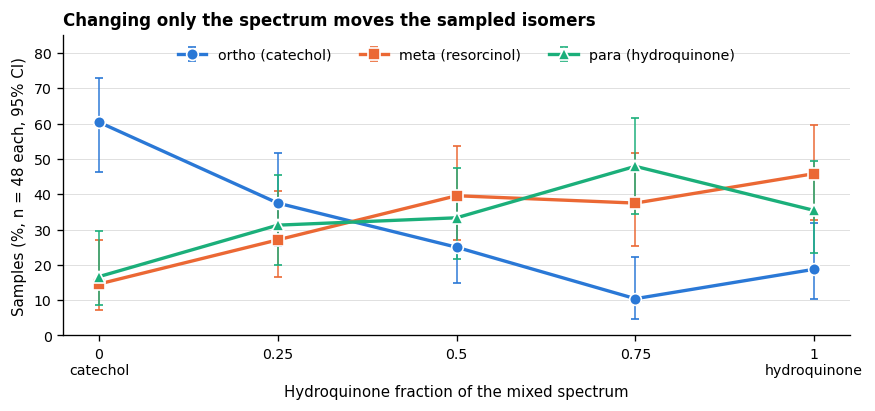

,ortho (catechol),meta (resorcinol),para (hydroquinone),other or invalid,valid
0.00,29,7,8,4,47
0.25,18,13,15,2,46
0.50,12,19,16,1,48
0.75,5,18,23,2,47
1.00,9,22,17,0,48


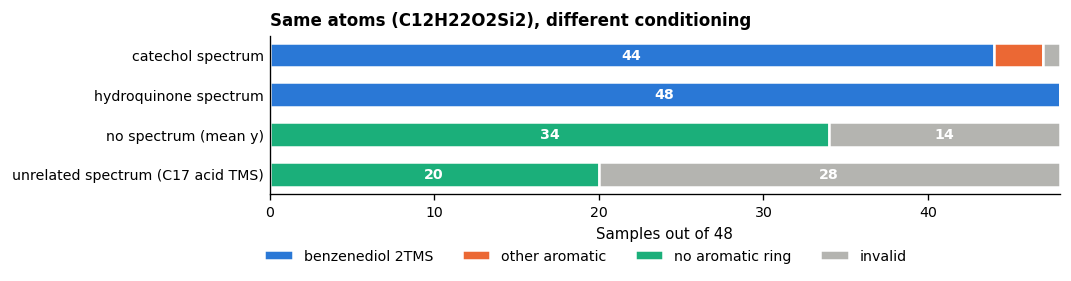

no spectrum (mean y of all 730) -> most sampled: [('CC1C=C[Si](C)(C)OC1CCO[Si](C)(C)C', 1), ('CC(C)[Si](C)(CCC=O)OCC[Si](C)(C)C', 1), ('CC(C=O)C[Si](C)(C)C(C)CCO[SiH](C)C', 1)]
unrelated spectrum (C17 acid TMS) -> most sampled: [('C[Si](C)(C)CCCCCC(=O)O[Si](C)(C)C', 9), ('C[Si](C)(C)O[Si](C)(C)CCCCCCC=O', 2), ('C[SiH](C)OC(=O)CCCCCC[Si](C)(C)C', 1)]
mixing at alpha = 0 reproduces the stored catechol y to within 8.0e-07


In [14]:
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]
N_MORPH = 48          # samples per condition, 3 batches of LIVE_BATCH
UNRELATED = 'LDY-20949'   # heptadecanoic acid TMS: a spectrum with nothing in common with the example


def mixed_tokens(alpha):
    """Tokens of (1 - alpha) * catechol + alpha * hydroquinone, mixed on the measured intensity scale.

    Same parent formula, so one m/z maps to one token in both spectra. The pipeline's steps are then redone:
    normalise to the base peak, square root, keep the 50 most intense peaks.
    """
    b, forms_a, inten_a = tokens_of(CATECHOL)
    _, forms_b, inten_b = tokens_of(HYDROQUINONE)
    mz_a, mz_b = peak_table(CATECHOL)['mz'].to_numpy(), peak_table(HYDROQUINONE)['mz'].to_numpy()
    form_of, I = {}, Counter()
    for mz, f, i in zip(mz_a, forms_a, inten_a):
        form_of[mz] = f
        I[mz] += (1 - alpha) * float(i) ** 2
    for mz, f, i in zip(mz_b, forms_b, inten_b):
        assert mz not in form_of or torch.equal(form_of[mz], f), f'token differs at m/z {mz}'
        form_of[mz] = f
        I[mz] += alpha * float(i) ** 2
    top = [mz for mz, v in I.most_common(50) if v > 0]
    peak = max(I[mz] for mz in top)
    return b, torch.stack([form_of[mz] for mz in top]), torch.tensor([(I[mz] / peak) ** 0.5 for mz in top], dtype=torch.float32)


def run_condition(y, seed):
    ex = example_of(CATECHOL)
    return sum((sample_chain(ex, y, LIVE_BATCH, seed + i)['smiles'] for i in range(N_MORPH // LIVE_BATCH)), [])


def morph_y(alpha):
    b, f, i = mixed_tokens(alpha)
    return encode(batch_from_tokens(b, f, i))


morph = {a: cached(f'morph_{a:.2f}', lambda a=a: run_condition(morph_y(a), SEED + int(a * 100))) for a in ALPHAS}
controls = {
    'no spectrum (mean y of all 730)': cached('control_mean_y', lambda: run_condition(torch.from_numpy(Y_MEAN)[None], SEED + 200)),
    'unrelated spectrum (C17 acid TMS)': cached('control_unrelated_y', lambda: run_condition(torch.from_numpy(y_of[UNRELATED])[None], SEED + 300)),
}


def tally(smiles):
    c = Counter(s for s in smiles)
    out = {k: c[Chem.CanonSmiles(v)] for k, v in ISOMERS.items()}
    out['other or invalid'] = len(smiles) - sum(out.values())
    return out


rows = pd.DataFrame({a: tally(morph[a]) for a in ALPHAS}).T
fig, ax = plt.subplots(figsize=(7.4, 3.5))
for c, col, mark in zip(cats[:3], colors, ('o', 's', '^')):
    p = rows[c] / N_MORPH * 100
    lo_hi = np.array([wilson(k, N_MORPH) for k in rows[c]]) * 100
    ax.errorbar(rows.index, p, yerr=[p - lo_hi[:, 0], lo_hi[:, 1] - p], color=col, marker=mark, markersize=7,
                markeredgecolor='white', linewidth=2, capsize=2.5, elinewidth=0.9, label=c)
ax.set(xlabel='Hydroquinone fraction of the mixed spectrum', ylabel=f'Samples (%, n = {N_MORPH} each, 95% CI)', ylim=(0, 85))
ax.set_xticks(ALPHAS, ['0\ncatechol', '0.25', '0.5', '0.75', '1\nhydroquinone'])
ax.set_title('Changing only the spectrum moves the sampled isomers')
ax.grid(axis='y', **GRID_KW)
ax.legend(loc='upper center', ncol=3)
plt.tight_layout()
plt.show()
display(rows.assign(valid=[sum(s is not None for s in morph[a]) for a in ALPHAS]))

# The same atoms under other conditioning: what kind of molecule comes out?
AROMATIC = Chem.MolFromSmarts('a')
_iso = {Chem.CanonSmiles(s) for s in ISOMERS.values()}


def kind_of(s):
    if s is None:
        return 'invalid'
    if s in _iso:
        return 'benzenediol 2TMS'
    return 'other aromatic' if Chem.MolFromSmiles(s).HasSubstructMatch(AROMATIC) else 'no aromatic ring'


KINDS, KIND_COLORS = ['benzenediol 2TMS', 'other aromatic', 'no aromatic ring', 'invalid'], [C1, C2, C3, NEUTRAL]
conditions = {'catechol spectrum': morph[0.0], 'hydroquinone spectrum': morph[1.0],
              'no spectrum (mean y)': controls['no spectrum (mean y of all 730)'],
              'unrelated spectrum (C17 acid TMS)': controls['unrelated spectrum (C17 acid TMS)']}
ctl = pd.DataFrame({k: Counter(map(kind_of, v)) for k, v in conditions.items()}).T.reindex(columns=KINDS).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(9, 2.6))
ypos, left = np.arange(len(ctl)), np.zeros(len(ctl))
for c, col in zip(KINDS, KIND_COLORS):
    ax.barh(ypos, ctl[c], left=left, height=0.62, color=col, edgecolor='white', linewidth=1.5, label=c)
    for y_, l_, v in zip(ypos, left, ctl[c]):
        if v >= 4:
            ax.text(l_ + v / 2, y_, f'{v}', ha='center', va='center', fontsize=8.5, color='white', fontweight='bold')
    left += ctl[c].to_numpy()
ax.set_yticks(ypos, ctl.index)
ax.invert_yaxis()
ax.set(xlim=(0, N_MORPH), xlabel=f'Samples out of {N_MORPH}')
ax.set_title(f'Same atoms ({EXAMPLE_FORMULA}), different conditioning')
ax.tick_params(axis='y', length=0)
ax.legend(loc='upper center', bbox_to_anchor=(0.4, -0.27), ncol=4)
plt.tight_layout()
plt.show()
for k, v in controls.items():
    top = Counter(s for s in v if s).most_common(3)
    print(k, '-> most sampled:', top)
_check = cached('morph_alpha0_check', lambda: float(np.abs(morph_y(0.0)[0].numpy() - y_of[CATECHOL]).max()))
print(f'mixing at alpha = 0 reproduces the stored catechol y to within {_check:.1e}')

**Mixing.** The share of ortho falls from 60% (95% CI 46–73) with pure catechol to 19% (10–32) with pure hydroquinone, and 10% at a fraction of 0.75. Adjacent steps have overlapping intervals, and meta and para are not separable within this noise, but the trend is clear. For a co-eluting pair, the output moves gradually rather than showing both isomers as separate high-count answers.

**Controls.** This is the clearest demonstration in the notebook:

- **Mean y:** none of 34 valid samples contains an aromatic ring, and all 34 are different. Without spectral information, the formula alone leads nowhere, and counts stay at 1.
- **C17 acid TMS y:** none of 20 valid samples is aromatic. The most common answer (9 of 48) is an aliphatic chain with a TMS ester, so the chemistry of the acid is carried over onto the atoms available.
- **Catechol or hydroquinone y:** 92 of 96 samples are benzenediol 2TMS, and all valid samples contain an aromatic ring.

The mean y is an average vector rather than a true absence of signal, and the decoder was not trained on it. Validity also falls under both controls, to 34 and 20 of 48, while it is 47–48 with a matching spectrum.


## 7. How often is it right?

Reference structures are available for 135 spectra of 107 distinct structures. A match means an identical 2D InChIKey. All 135 are real measured spectra.


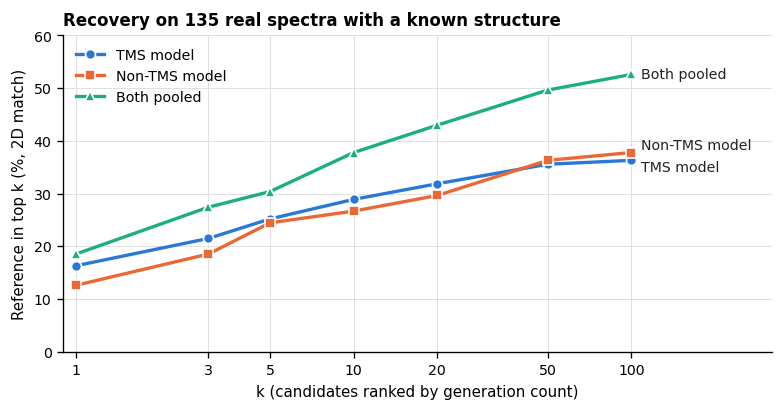

,top-1,top-3,top-5,top-10,top-20,top-50,top-100
TMS model,0.163,0.215,0.252,0.289,0.319,0.356,0.363
Non-TMS model,0.126,0.185,0.244,0.267,0.296,0.363,0.378
Both pooled,0.185,0.274,0.304,0.378,0.430,0.496,0.526


107 unique 2D structures among 135 spectra; mean rank-1 Tanimoto 0.38


In [15]:
lab_rows = []
for uid, r in refs.iterrows():
    true_mol = Chem.MolFromInchi(r['inchi'])
    assert CalcMolFormula(true_mol) == r['formula'], uid
    key = key_2d(r['inchi'])
    g = by_uid.get(uid)
    keys = [] if g is None else g['key_2d'].tolist()
    rank = keys.index(key) + 1 if key in keys else np.nan
    fp_true = morgan(true_mol)
    top1 = None if g is None else Chem.MolFromSmiles(g['smiles'].iloc[0])
    lab_rows.append({'uid': uid, 'name': labels.loc[uid, 'compound_name'], 'formula': r['formula'], 'key': key,
                     'smiles': Chem.MolToSmiles(true_mol), 'rank': rank,
                     'count_true': 0 if rank != rank else int(g['count'].iloc[int(rank) - 1]),
                     'top_count': 0 if g is None else int(g['count'].iloc[0]),
                     'n_unique': 0 if g is None else len(g),
                     'validity': summary.loc[uid, 'validity_rate'],
                     'heavy': true_mol.GetNumHeavyAtoms(),
                     'nSi': sum(a.GetSymbol() == 'Si' for a in true_mol.GetAtoms()),
                     'tanimoto_top1': 0.0 if top1 is None else DataStructs.TanimotoSimilarity(morgan(top1), fp_true),
                     'top1_formula_ok': False if g is None else bool(g['formula_match'].iloc[0])})
lab = pd.DataFrame(lab_rows).set_index('uid')

# Seen = the same connectivity (first InChIKey block) is in the training split, with a simulated spectrum.
train_blocks = set(_train['inchikey'].str[:14])
lab['seen_in_training'] = [refs.loc[u, 'inchikey'][:14] in train_blocks for u in lab.index]


def ranked_keys(c):
    return {u: g['key_2d'].tolist() for u, g in c.groupby('uid', sort=False)}


def pool(a, b):
    """Candidates of both models by summed count, interleaved so that ties favour neither (as in inspect_yee_candidates)."""
    out = {}
    for u in lab.index:
        counts = Counter()
        ga = a[a['uid'] == u]
        gb = b[b['uid'] == u]
        for pair in zip_longest(zip(ga['key_2d'], ga['count']), zip(gb['key_2d'], gb['count'])):
            for p in pair:
                if p is not None:
                    counts[p[0]] += p[1]
        out[u] = [k for k, _ in counts.most_common()]
    return out


def topk_curve(rk):
    return [np.mean([lab.loc[u, 'key'] in rk.get(u, [])[:k] for u in lab.index]) for k in TOP_K_LIST]


rk_tms, rk_notms, rk_pool = ranked_keys(cand), ranked_keys(cand_notms), pool(cand, cand_notms)
curves = {'TMS model': topk_curve(rk_tms), 'Non-TMS model': topk_curve(rk_notms), 'Both pooled': topk_curve(rk_pool)}

fig, ax = plt.subplots(figsize=(6.6, 3.5))
for (name_, c), col, mark in zip(curves.items(), (C1, C2, C3), ('o', 's', '^')):
    ax.plot(TOP_K_LIST, np.array(c) * 100, color=col, marker=mark, markersize=6, markeredgecolor='white', linewidth=2, label=name_)
    ax.text(TOP_K_LIST[-1] * 1.08, c[-1] * 100 + {'TMS model': -1.3, 'Non-TMS model': 1.3}.get(name_, 0), name_,
            va='center', fontsize=8.5, color=INK)
ax.set_xscale('log')
ax.set_xticks(TOP_K_LIST, TOP_K_LIST)
ax.minorticks_off()
ax.set(xlabel='k (candidates ranked by generation count)', ylabel='Reference in top k (%, 2D match)', ylim=(0, 60), xlim=(0.9, 320))
ax.set_title(f'Recovery on {len(lab)} real spectra with a known structure')
ax.grid(**GRID_KW)
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()
display(pd.DataFrame(curves, index=[f'top-{k}' for k in TOP_K_LIST]).T.round(3))
print(f'{lab["key"].nunique()} unique 2D structures among {len(lab)} spectra; mean rank-1 Tanimoto {lab["tanimoto_top1"].mean():.2f}')

In [16]:
# Does training overlap explain the score? And how far is real from simulated?
def seen_row(x):
    n = len(x)
    k1, k10 = int((x['rank'] == 1).sum()), int((x['rank'] <= 10).sum())
    return pd.Series({'spectra': n, 'structures': x['key'].nunique(), 'top-1': k1 / n, 'top-1 95% CI': '%.2f-%.2f' % wilson(k1, n),
                      'top-10': k10 / n, 'top-10 95% CI': '%.2f-%.2f' % wilson(k10, n),
                      'rank-1 Tanimoto': x['tanimoto_top1'].mean()})


display(pd.DataFrame({'not in training': seen_row(lab[~lab['seen_in_training']]),
                      'in training': seen_row(lab[lab['seen_in_training']])}).T.round(3))

# Exp4 test set (non-TMS model, simulated spectra), from feature_difficulty_analysis_ddp.ipynb, section 2.
# Exact InChI match there, so exact InChI here too; those molecules carry no stereo.
EXP4_SIM_TEST = {1: 0.2345, 3: 0.3622, 5: 0.4143, 10: 0.4758, 20: 0.5182, 50: 0.5481, 100: 0.5581}
_exact = {u: g['inchi'].tolist() for u, g in cand_notms.groupby('uid', sort=False)}
real_all = [np.mean([Chem.MolToInchi(Chem.MolFromInchi(refs.loc[u, 'inchi'])) in _exact.get(u, [])[:k] for u in lab.index]) for k in TOP_K_LIST]
no_si = lab.index[lab['nSi'] == 0]
real_no_si = [np.mean([Chem.MolToInchi(Chem.MolFromInchi(refs.loc[u, 'inchi'])) in _exact.get(u, [])[:k] for u in no_si]) for k in TOP_K_LIST]
real_no_si_2d = [np.mean([lab.loc[u, 'key'] in rk_notms.get(u, [])[:k] for u in no_si]) for k in TOP_K_LIST]
display(pd.DataFrame({'simulated test set (n = 7,535)': [EXP4_SIM_TEST[k] for k in TOP_K_LIST],
                      f'real, all references (n = {len(lab)})': real_all,
                      f'real, no Si in structure (n = {len(no_si)})': real_no_si,
                      f'same, 2D match': real_no_si_2d},
                     index=[f'top-{k}' for k in TOP_K_LIST]).T.round(3))

,spectra,structures,top-1,top-1 95% CI,top-10,top-10 95% CI,rank-1 Tanimoto
not in training,108,86,0.157407,0.10-0.24,0.287037,0.21-0.38,0.365829
in training,27,21,0.185185,0.08-0.37,0.296296,0.16-0.48,0.419884


,top-1,top-3,top-5,top-10,top-20,top-50,top-100
"simulated test set (n = 7,535)",0.234,0.362,0.414,0.476,0.518,0.548,0.558
"real, all references (n = 135)",0.119,0.178,0.230,0.252,0.281,0.341,0.356
"real, no Si in structure (n = 25)",0.040,0.080,0.080,0.120,0.120,0.200,0.200
"same, 2D match",0.040,0.080,0.080,0.120,0.120,0.240,0.240


**Accuracy.** The TMS model has the reference at rank 1 for 22 of 135 spectra (16%, 95% CI about 11–23%) and in the top 10 for 29%. It tops out at 36% because 100 samples often never produce the true structure.

**Pooling.** The two models have close accuracy on their own, but pooling takes the top-100 figure from 36–38% to 53%, so they find different structures. Pooling uses 200 samples, not 100, so this is partly a sampling effect.

**Training overlap does not explain the score.** Structures not in training have top-1 16% and top-10 29%, close to the 19% and 30% for those that are, with wide and overlapping intervals. Overlap here is with a simulated spectrum of the same structure, since no real spectra are used in training.

**Simulated against real.** On simulated test spectra, the non-TMS model reaches top-1 23% and top-100 56%. On real spectra it reaches 12% and 36%. That comparison is not like for like, since the chemistry differs and the real set is mostly derivatised. The closest match, real spectra of compounds with no Si (n = 25), is much lower still at 4% and 20%, though with a small sample. We take the non-TMS run to be Exp4 from git history, not from a stored record.

**Limits of these numbers.** References exist only for compounds named well enough to look up, which skews towards the easy cases. Repeat spectra of one compound are not independent. The 135 are not a random sample of the library.


## 8. When should you believe it?

For an unknown there is no reference, so the question is whether the model's output says anything about its own reliability. The count of the rank-1 structure is the natural candidate.


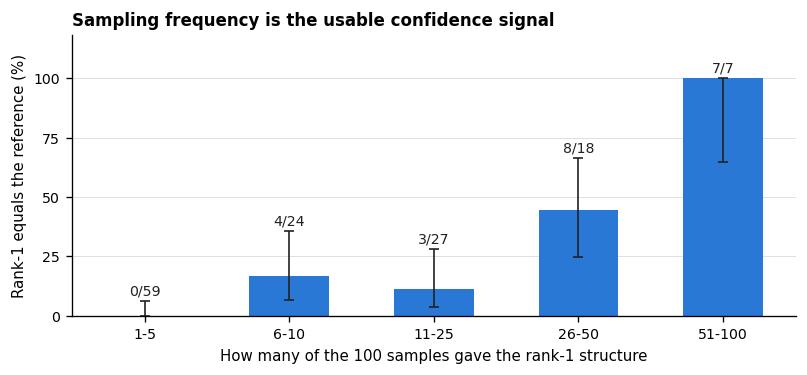

rank-1 count,labelled spectra,rank-1 correct,rate,rank-1 Tanimoto,all spectra in the run
1-5,59,0,0.00,0.22,459
6-10,24,4,0.17,0.41,107
11-25,27,3,0.11,0.33,89
26-50,18,8,0.44,0.66,42
51-100,7,7,1.00,1.00,17


top-1: ranking by count finds 22/135, by cos(y, fingerprint) 8/135
top-10: ranking by count finds 39/135, by cos(y, fingerprint) 32/135


In [17]:
BINS = [(1, 5), (6, 10), (11, 25), (26, 50), (51, 100)]
all_top = cand.groupby('uid', sort=False)['count'].first()
rel = []
for lo, hi in BINS:
    x = lab[(lab['top_count'] >= lo) & (lab['top_count'] <= hi)]
    k = int((x['rank'] == 1).sum())
    rel.append({'rank-1 count': f'{lo}-{hi}', 'labelled spectra': len(x), 'rank-1 correct': k, 'rate': k / max(len(x), 1),
                'lo': wilson(k, len(x))[0], 'hi': wilson(k, len(x))[1], 'rank-1 Tanimoto': x['tanimoto_top1'].mean(),
                'all spectra in the run': int(((all_top >= lo) & (all_top <= hi)).sum())})
rel = pd.DataFrame(rel)

fig, ax = plt.subplots(figsize=(6.8, 3.2))
xp = np.arange(len(rel))
ax.bar(xp, rel['rate'] * 100, width=0.55, color=C1)
ax.errorbar(xp, rel['rate'] * 100, yerr=[(rel['rate'] - rel['lo']) * 100, (rel['hi'] - rel['rate']) * 100], fmt='none',
            ecolor=INK, elinewidth=1, capsize=3)
for i, r in rel.iterrows():
    ax.text(i, r['hi'] * 100 + 2.5, f"{r['rank-1 correct']}/{r['labelled spectra']}", ha='center', fontsize=8.5, color=INK)
ax.set_xticks(xp, rel['rank-1 count'])
ax.set(xlabel=f'How many of the {N_SAMPLES} samples gave the rank-1 structure', ylabel='Rank-1 equals the reference (%)', ylim=(0, 118))
ax.set_yticks([0, 25, 50, 75, 100])
ax.set_title('Sampling frequency is the usable confidence signal')
ax.grid(axis='y', **GRID_KW)
plt.tight_layout()
plt.show()
display(rel.drop(columns=['lo', 'hi']).style.hide(axis='index').format(precision=2))

# Competing signal: cos(y, candidate fingerprint), as in inspect_yee_candidates.ipynb
by_cos = {u: g.sort_values('cos_fp', ascending=False, kind='stable')['key_2d'].tolist() for u, g in by_uid.items()}
for k in (1, 10):
    n_cnt = sum(lab.loc[u, 'key'] in rk_tms.get(u, [])[:k] for u in lab.index)
    n_cos = sum(lab.loc[u, 'key'] in by_cos.get(u, [])[:k] for u in lab.index)
    print(f'top-{k}: ranking by count finds {n_cnt}/{len(lab)}, by cos(y, fingerprint) {n_cos}/{len(lab)}')

In [18]:
# The spectra with the highest count that the reference table does not cover: a harder test of the signal above.
top_rows = cand.groupby('uid', sort=False).head(1).set_index('uid')
high = top_rows[top_rows['count'] > 50].copy()
high['library name'] = labels['compound_name'].reindex(high.index).str.replace('\n', ' ').str.slice(0, 44)
high['has reference'] = high.index.isin(lab.index)
# Spectra without a reference, judged by reading the library name against the candidate. Not a computed result.
READING = {'LDY-19049': 'right (library formula has 2 H too many)', 'LDY-18390': 'right (library formula has 2 H too many)',
           'LDY-19008': 'right', 'LDY-19030': 'wrong: 4-methyl, not 3-methyl', 'LDY-20553': 'wrong: 4-methyl, not 3-methyl',
           'LDY-18977': 'wrong: 1,2,4-triol, not 1,2,3', 'LDY-19029': 'wrong: aldehyde with two silyl ethers, not an acid',
           'LDY-20936': 'open: named only as a pyrogallol isomer', 'LDY-21484': 'open: unidentified', 'LDY-21261': 'open: unidentified'}
high['verdict'] = ['reference: ' + ('right' if lab.loc[u, 'rank'] == 1 else 'wrong') if u in lab.index else 'by name, ' + READING[u]
                   for u in high.index]
pd.set_option('display.max_colwidth', 60)
display(high.sort_values('count', ascending=False)[['library name', 'smiles', 'count', 'verdict']])
print(high['verdict'].str.extract(r'(reference: \w+|right|wrong|open)')[0].value_counts().to_string())

,library name,smiles,count,verdict
uid,,,,
LDY-19049,Benzoic acid TMS steroisomer 1,C[Si](C)(C)OC(=O)c1ccccc1,94,"by name, right (library formula has 2 H too many)"
LDY-20936,Pyrogallol isomer 3TMS,C[Si](C)(C)Oc1ccc(O[Si](C)(C)C)c(O[Si](C)(C)C)c1,81,"by name, open: named only as a pyrogallol isomer"
LDY-21086,benzophenone,O=C(c1ccccc1)c1ccccc1,76,reference: right
LDY-19646,"Silanol, trimethyl-, phosphate (3:1)",C[Si](C)(C)OP(=O)(O[Si](C)(C)C)O[Si](C)(C)C,75,reference: right
LDY-6968,"Glycerol, 3TMS derivative",C[Si](C)(C)OCC(CO[Si](C)(C)C)O[Si](C)(C)C,73,reference: right
LDY-19030,"3-methylbenzene-1,2-diol 2TMS",Cc1ccc(O[Si](C)(C)C)c(O[Si](C)(C)C)c1,68,"by name, wrong: 4-methyl, not 3-methyl"
LDY-18977,"Benzene-1,2,3-triol 3TMS",C[Si](C)(C)Oc1ccc(O[Si](C)(C)C)c(O[Si](C)(C)C)c1,67,"by name, wrong: 1,2,4-triol, not 1,2,3"
LDY-16557,4-Phenylphenol TMS,C[Si](C)(C)Oc1ccc(-c2ccccc2)cc1,66,reference: right
LDY-20553,3-Methylcatechol 2TMS,Cc1ccc(O[Si](C)(C)C)c(O[Si](C)(C)C)c1,59,"by name, wrong: 4-methyl, not 3-methyl"


reference: right    7
wrong               4
right               3
open                3


**Count works as a signal, in a limited way.** Rank-1 was right in none of 59 labelled spectra with a count of 5 or less, and in 7 of 7 above 50. It also beats the alternative: ranking by count finds 22 at top-1, against 8 for cos(y, fingerprint). The middle bins are not monotonic (4/24, then 3/27), and those intervals are wide.

**Most of the library sits at the low end.** 459 of the 714 spectra with any valid candidate have a rank-1 count of 5 or less, so for most spectra the model is effectively saying that it does not know.

**The 7 of 7 is optimistic.** The table above extends the top bin to the spectra lacking a reference, judged by reading library names against candidates. This is a hand reading, not a computed result. Of 17 spectra above 50:

- 7 are right by reference.
- 3 are right by name. Two of them are benzoic acid TMS, whose library formula, C10H16O2Si, has 2 more H than the compound's C10H14O2Si, so our formula check wrongly fails them.
- 4 are wrong by name: three pick the wrong ring position with high confidence (59–68 of 100), and one is the wrong functional group.
- 3 are open.

So among the 14 we can judge, 10 are right. A high count means the model has found the right kind of molecule, and often the right one, but it **does not** guarantee the ring position.


## 9. What chemistry does it get right?

An exact match is a harsh test. Does rank-1 at least contain the correct functional groups? Recall below is the share of reference spectra containing a motif where the rank-1 candidate also has it; precision is the reverse. The two accuracy columns are for spectra whose true structure contains the motif.


In [19]:
motif_q_all = {'aromatic ring': MOTIF_Q['aromatic ring'], 'TMS ester': MOTIF_Q['TMS ester'],
               'of which aromatic TMS ester': Chem.MolFromSmarts('c-C(=O)O[Si](C)(C)C'),
               'of which aliphatic TMS ester': Chem.MolFromSmarts('[CX4]C(=O)O[Si](C)(C)C'),
               'aryl O-TMS': MOTIF_Q['aryl O-TMS'], 'alkyl O-TMS': MOTIF_Q['alkyl O-TMS'],
               'siloxane Si-O-Si': Chem.MolFromSmarts('[Si]O[Si]')}
rows = []
ref_mols = {u: Chem.MolFromSmiles(s) for u, s in lab['smiles'].items()}
top1_mols = {u: Chem.MolFromSmiles(top_rows.loc[u, 'smiles']) for u in lab.index if u in top_rows.index}
for name_, q in motif_q_all.items():
    has_true = pd.Series({u: m.HasSubstructMatch(q) for u, m in ref_mols.items()})
    has_top1 = pd.Series({u: top1_mols[u].HasSubstructMatch(q) if u in top1_mols else False for u in ref_mols})
    tp, fn, fp = int((has_true & has_top1).sum()), int((has_true & ~has_top1).sum()), int((~has_true & has_top1).sum())
    x = lab[has_true.reindex(lab.index)]
    rows.append({'motif': name_, 'spectra with it': int(has_true.sum()),
                 'recall in rank-1': tp / max(tp + fn, 1), 'precision in rank-1': tp / max(tp + fp, 1),
                 'top-1 accuracy': (x['rank'] == 1).mean(), 'top-10 accuracy': (x['rank'] <= 10).mean()})
x = lab[lab['nSi'] == 0]
rows.append({'motif': 'no Si at all', 'spectra with it': len(x), 'top-1 accuracy': (x['rank'] == 1).mean(), 'top-10 accuracy': (x['rank'] <= 10).mean()})
display(pd.DataFrame(rows).round(2).style.hide(axis='index').format(na_rep='-', precision=2))

oosi = Chem.MolFromSmarts('[OX2]([OX2])[Si]')
print(f'rank-1 candidates over all spectra with an O-O-Si group: '
      f'{np.mean([Chem.MolFromSmiles(s).HasSubstructMatch(oosi) for s in top_rows["smiles"]]):.0%}')
print(f'rank-1 candidates with the wrong H count: labelled {1 - lab["top1_formula_ok"].mean():.0%}, '
      f'all spectra {1 - top_rows["formula_match"].mean():.0%}')
print('mean validity by heavy atoms (all labelled):')
print(lab.groupby(pd.cut(lab['heavy'], [0, 15, 20, 25, 30, 60]))['validity'].mean().round(2).to_string())
_all_h = summary.join(pd.Series({u: sum(int(n or 1) for e, n in re.findall(r'([A-Z][a-z]?)(\d*)', f) if e != 'H')
                                 for u, f in summary['formula'].items()}, name='heavy'))
print(f'spectra with no valid candidate: {(summary["num_valid"] == 0).sum()} of {len(summary)}, '
      f'median {_all_h.loc[_all_h["num_valid"] == 0, "heavy"].median():.0f} heavy atoms; those with C and H only: '
      f'{sum(set(re.findall("[A-Z][a-z]?", f)) <= {"C", "H"} for f in summary.loc[summary["num_valid"] == 0, "formula"])}')

motif,spectra with it,recall in rank-1,precision in rank-1,top-1 accuracy,top-10 accuracy
aromatic ring,50,0.90,0.94,0.16,0.26
TMS ester,57,0.19,1.00,0.09,0.14
of which aromatic TMS ester,9,0.33,1.00,0.22,0.44
of which aliphatic TMS ester,48,0.15,1.00,0.06,0.08
aryl O-TMS,29,0.90,0.90,0.21,0.34
alkyl O-TMS,39,0.95,0.53,0.15,0.44
siloxane Si-O-Si,5,1.00,0.71,0.60,0.60
no Si at all,25,-,-,0.04,0.04


rank-1 candidates over all spectra with an O-O-Si group: 13%
rank-1 candidates with the wrong H count: labelled 50%, all spectra 60%
mean validity by heavy atoms (all labelled):
heavy
(0, 15]     0.95
(15, 20]    0.90
(20, 25]    0.78
(25, 30]    0.71
(30, 60]    0.71
spectra with no valid candidate: 16 of 730, median 29 heavy atoms; those with C and H only: 16


Recovered: top row is the reference, bottom row the rank-1 candidate


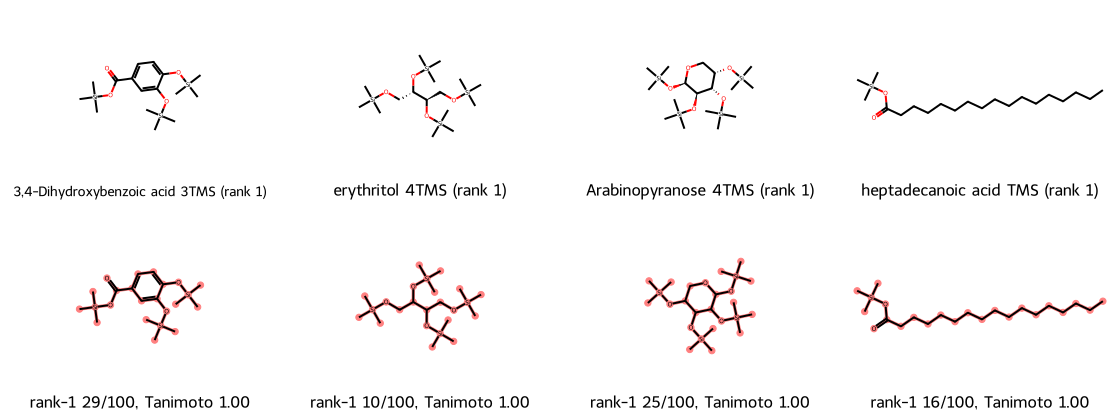

Close: right class, wrong position, chain or group


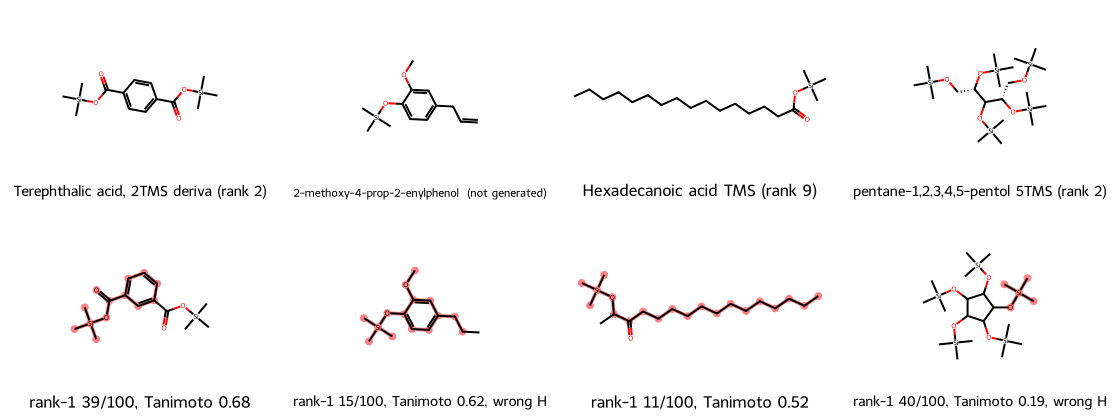

Wrong: the silyl ester blind spot, and compounds without Si


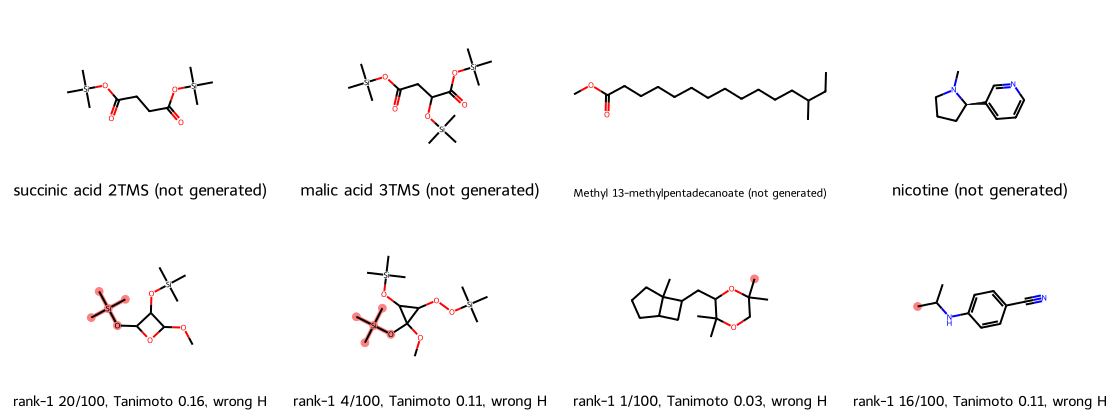

In [20]:
def versus(uids):
    """Reference above rank-1 candidate, with the maximum common substructure highlighted in the candidate."""
    mols, legends, highlight = [], [], []
    for u in uids:
        t, c = ref_mols[u], top1_mols[u]
        mcs = rdFMCS.FindMCS([t, c], timeout=3, ringMatchesRingOnly=True, completeRingsOnly=True)
        patt = Chem.MolFromSmarts(mcs.smartsString)
        r = lab.loc[u]
        short = re.sub(r'\s+', ' ', str(r['name']))[:30]
        rank_txt = 'not generated' if r['rank'] != r['rank'] else f"rank {int(r['rank'])}"
        mols.extend([t, c])
        legends.extend([f'{short} ({rank_txt})',
                        f"rank-1 {r['top_count']}/{N_SAMPLES}, Tanimoto {r['tanimoto_top1']:.2f}"
                        + ('' if r['top1_formula_ok'] else ', wrong H')])
        highlight.extend([[], list(c.GetSubstructMatch(patt))])
    # Molecule pairs read top to bottom, so transpose the column order into the row-wise grid
    n = len(uids)
    order = list(range(0, 2 * n, 2)) + list(range(1, 2 * n, 2))
    return Draw.MolsToGridImage([mols[i] for i in order], molsPerRow=n, subImgSize=(280, 210),
                                legends=[legends[i] for i in order], highlightAtomLists=[highlight[i] for i in order])


GOOD = ['LDY-16805', 'LDY-20796', 'LDY-20828', 'LDY-20949']   # 3,4-DHBA 3TMS, erythritol 4TMS, arabinopyranose 4TMS, C17 acid TMS
NEAR = ['LDY-19729', 'LDY-16717', 'LDY-18973', 'LDY-18928']   # terephthalic acid 2TMS, eugenol TMS, C16 acid TMS, a pentitol 5TMS
BAD  = ['LDY-20761', 'LDY-20948', 'LDY-20868', 'LDY-21096']   # succinic acid 2TMS, malic acid 3TMS, a branched FAME, nicotine
print('Recovered: top row is the reference, bottom row the rank-1 candidate')
display(versus(GOOD))
print('Close: right class, wrong position, chain or group')
display(versus(NEAR))
print('Wrong: the silyl ester blind spot, and compounds without Si')
display(versus(BAD))

**What works.** Aromatic rings (recall 0.90, precision 0.94) and aryl O-TMS (0.90, 0.90). Alkyl O-TMS has high recall (0.95), but only 0.53 precision: the model proposes it too readily. When sugars and polyols are recovered, it is at modest counts: erythritol at 10 of 100, arabinopyranose at 25.

**Near misses are chemically sensible.** Terephthalic acid gets its meta isomer, and eugenol gets the propyl analogue, which is the same heavy atoms with the wrong H count. Hexadecanoic acid is in the top 10 but behind a keto-silyl ether.

**TMS esters are the largest gap.** 57 references contain one, 42% of the set, and rank-1 recall is 0.19. Aliphatic ones are worst, with recall 0.15 and top-10 accuracy 8% (n = 48). Aromatic ones do better, with 0.33 and 44% (n = 9). Succinic and malic acid are never generated at all. The model proposes silyl ethers and small rings instead. When it does propose an ester, the reference has one too (precision 1.00). Training data do not explain it, since 27% of GECKO-A molecules have this group. One untested possibility is that NEIMS simulates these spectra differently from real ones. Your view would help here.

**Other systematic errors:**

- **Hydrogen count.** 50% of rank-1 candidates in labelled spectra have the wrong H count, and 60% across the library. Filtering to candidates that match the formula is cheap, and would be an obvious next step.
- **O-O-Si groups** in 13% of rank-1 candidates, none in references. This pattern is common in GECKO-A.
- **Compounds with no Si** reach only 4% top-1 and top-10. These are outside most of the training chemistry; nicotine and a branched methyl ester are shown above.
- **Validity falls with size**, from 0.95 at up to 15 heavy atoms to 0.71 above 25. All 16 spectra with no valid candidate have hydrocarbon formulas, with a median of 29 carbons.


## 10. Hypotheses for unidentified spectra

This is the intended use: 253 of 730 spectra have no name. These are the unidentified spectra without a reference whose rank-1 candidate matches the formula and has a count of at least 26, the range where labelled spectra were right 44% or more of the time. Formulas are as listed in the library; we have not checked how they were assigned.

These are **hypotheses to test against standards**, not identifications.


,library code,campaign,formula,smiles,count,RI
uid,,,,,,
LDY-21484,UNK_AHG_HZ_SOAS_369,SOAS 2013,C15H30O3Si3,C[Si](C)(C)Oc1ccc(O[Si](C)(C)C)c(O[Si](C)(C)C)c1,56,1534.0
LDY-21261,UNK_AHG_HZ_SOAS_146,SOAS 2013,C15H30O3Si3,C[Si](C)(C)Oc1ccc(O[Si](C)(C)C)c(O[Si](C)(C)C)c1,51,1596.0
LDY-21203,UNK_AHG_HZ_SOAS_88,SOAS 2013,C16H40O5Si4,C[Si](C)(C)OC1OC(O[Si](C)(C)C)C(O[Si](C)(C)C)C1O[Si](C)(C)C,38,1526.0
LDY-21754,UNK_AHG_HZ_SOAS_639,SOAS 2013,C8H13NO4,CC(=O)C1CC(O[N+](=O)[O-])C1(C)C,35,1422.0
LDY-20671,UNK_2553 2TMS,Napa Fires 2017,C13H30O3Si2,CC(=O)CCC(O[Si](C)(C)C)C(C)O[Si](C)(C)C,29,1512.0
LDY-20583,UNK_2309 TMS,Napa Fires 2017,C12H16O2Si,C[Si](C)(C)Oc1ccc2c(c1)CCC2=O,28,1630.0
LDY-20798,UNK_3830 2TMS,Napa Fires 2017,C16H30O2Si2,CCC(C)(O[Si](C)(C)C)c1ccc(O[Si](C)(C)C)cc1,26,1772.0


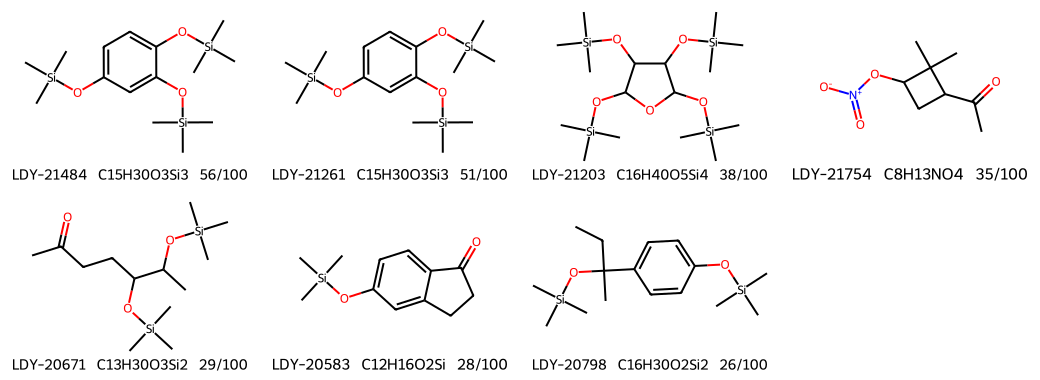

uid,library name,RI,rank-1 count,top peaks
LDY-18977,"Benzene-1,2,3-triol 3TMS",1530,67,"239 (100%), 73 (81%), 342 (24%), 240 (19%), 211 (15%), 133 (10%)"
LDY-20936,Pyrogallol isomer 3TMS,1536,81,"239 (100%), 73 (76%), 342 (34%), 240 (20%), 211 (14%), 343 (10%)"
LDY-21484,UNK_AHG_HZ_SOAS_369,1534,56,"239 (100%), 73 (84%), 342 (24%), 211 (18%), 240 (15%), 45 (11%)"
LDY-21261,UNK_AHG_HZ_SOAS_146,1596,51,"239 (100%), 342 (79%), 219 (23%), 343 (19%), 292 (13%), 344 (6%)"


In [20]:
named_tentative = refs.index
unknown = top_rows[(~labels['identified'].reindex(top_rows.index).fillna(False).astype(bool))
                   & (top_rows['count'] >= 26) & top_rows['formula_match'] & ~top_rows.index.isin(named_tentative)].copy()
unknown = unknown.sort_values('count', ascending=False)
unknown['library code'] = labels['compound_name'].reindex(unknown.index)
unknown['campaign'] = labels['source'].reindex(unknown.index)
unknown['RI'] = labels['RI'].reindex(unknown.index)
display(unknown[['library code', 'campaign', 'formula', 'smiles', 'count', 'RI']])
display(Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in unknown['smiles']], molsPerRow=4, subImgSize=(260, 190),
                             legends=[f"{u}  {r['formula']}  {r['count']}/{N_SAMPLES}" for u, r in unknown.iterrows()]))


def top_peaks(uid, n=6):
    mz, inten = raw_spectrum(uid)
    return ', '.join(f'{mz[i]:.0f} ({inten[i]:.0%})' for i in np.argsort(-inten)[:n])


# Same rank-1 candidate, 1,2,4-benzenetriol 3TMS, for four spectra. Retention index and the spectrum tell them apart.
display(pd.DataFrame([{'uid': u, 'library name': labels.loc[u, 'compound_name'], 'RI': int(labels.loc[u, 'RI']),
                       'rank-1 count': int(top_rows.loc[u, 'count']), 'top peaks': top_peaks(u)}
                      for u in ('LDY-18977', 'LDY-20936', 'LDY-21484', 'LDY-21261')]).style.hide(axis='index'))

**Retention index can check these answers, and in the last table it does.** All four spectra get the same rank-1 structure, 1,2,4-benzenetriol 3TMS, so they test the model's answer against independent information:

- LDY-18977 is named as pyrogallol (the 1,2,3-triol), and the candidate is wrong by name.
- LDY-20936 and LDY-21484 have nearly the same peak pattern and RI (1530–1536) as LDY-18977. They are probably the same compound as each other and as LDY-18977, and not what the model says.
- LDY-21261 has a clearly different spectrum, with m/z 342 at 79% and a new peak at 219, and RI 1596. It is a different compound with the same formula. It may be the true 1,2,4-triol, but that needs a standard.

So the model's answer for LDY-21484, at 56 of 100, is probably wrong in ring position, even though the class is likely right. A retention-index check could catch this kind of error, given measured or predicted RI for the candidates, and almost the whole library has an RI (726 of 730).


## 11. Explore any spectrum

Choose a spectrum from the list; those with a reference come first. Use `show_case('LDY-####')` directly if widgets are not available. The dropdown does not appear in a static view, so one example is shown below it: 3,4-dihydroxybenzoic acid 3TMS, a good case, where the correct structure ranks first and the other high-ranked candidates are its positional isomers and aldehyde analogues.


In [21]:
def show_case(uid, k=9):
    """Spectrum, reference if there is one, and the top candidates."""
    name = re.sub(r'\s+', ' ', str(labels.loc[uid, 'compound_name']))
    s = summary.loc[uid]
    print(f"{uid}  {name}  |  {labels.loc[uid, 'formula']}  |  {labels.loc[uid, 'source']}  |  "
          f"{s['num_valid']}/{s['num_samples']} valid, {s['unique_valid']} unique")
    mz, inten = raw_spectrum(uid)
    kept = np.isin(mz, peak_table(uid)['mz'])
    fig, ax = plt.subplots(figsize=(10, 2.6))
    ax.vlines(mz[~kept], 0, inten[~kept] * 100, color=NEUTRAL, linewidth=0.8)
    ax.vlines(mz[kept], 0, inten[kept] * 100, color=C1, linewidth=1.1)
    for i in np.argsort(-inten)[:7]:
        ax.text(mz[i], inten[i] * 100 + 2, f'{mz[i]:.0f}', ha='center', fontsize=8, color=INK)
    ax.set(xlabel='m/z', ylabel='Relative intensity (%)', ylim=(0, 115))
    ax.grid(axis='y', **GRID_KW)
    plt.tight_layout()
    plt.show()
    display(grid_for(uid, k=k))


try:
    import ipywidgets as widgets
    _options = sorted(((re.sub(r'\s+', ' ', str(labels.loc[u, 'compound_name']))[:46] + f'  [{u}]', u) for u in names),
                      key=lambda p: (p[1] not in lab.index, p[0]))
    display(widgets.interactive(show_case, uid=widgets.Dropdown(options=_options, value=CATECHOL, description='spectrum',
                                                                layout=widgets.Layout(width='620px')),
                                k=widgets.IntSlider(value=9, min=1, max=19, description='candidates')))
except ImportError:
    print("ipywidgets not installed: call show_case('LDY-####') directly.")

interactive(children=(Dropdown(description='spectrum', index=106, layout=Layout(width='620px'), options=(('(1R…

LDY-16805  3,4-Dihydroxybenzoic acid 3TMS  |  C16H30O4Si3  |  Fire Lab FIREX 2016  |  99/100 valid, 22 unique


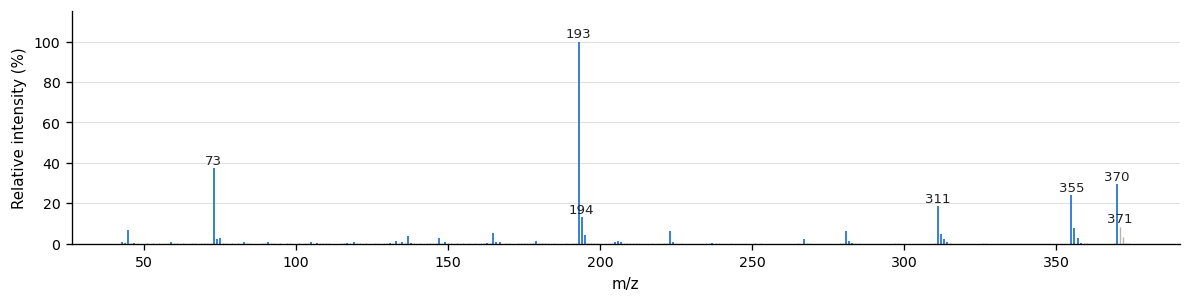

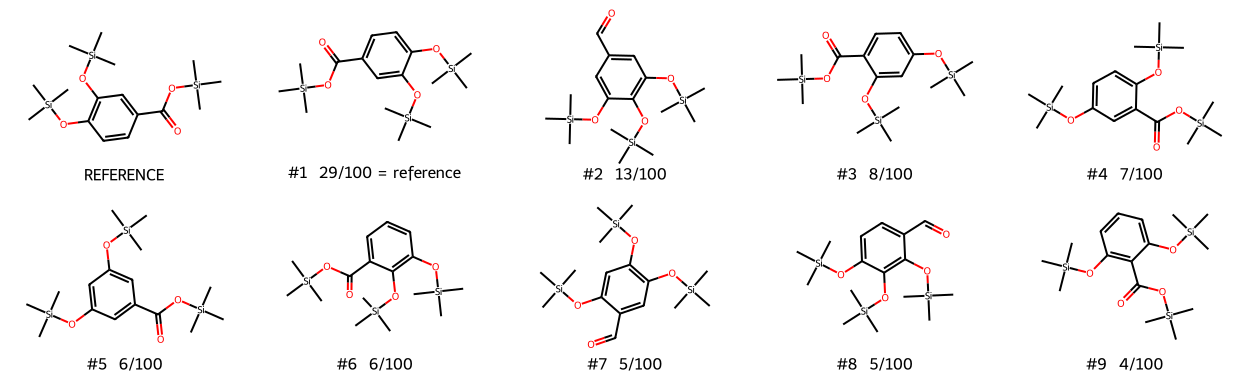

In [23]:
show_case('LDY-16805')

## 12. Limitations and questions for you

**What limits use today**

| Limitation | Effect |
|---|---|
| The formula must be given | With real unknowns, a wrong formula cannot be recovered from. |
| Trained on simulated spectra only | Accuracy falls sharply on real spectra (§7). |
| Unit-mass tokens are not ion assignments | Known fragment chemistry is not available to the model (§3). |
| Hydrogens are implicit, and there is no formula filter | Half of rank-1 candidates have the wrong H count (§9). |
| No retention information | Isomers that RI separates stay confused (§6, §10). |
| 2D structures only | No stereoisomers. |
| Only 135 references | All statements about confidence rest on a small and selected set (§8). |

**Questions for you**

1. **Usefulness.** A ranked list is right about 16% of the time at rank 1 and 29% in the top 10, plus a confidence signal that picks out the better cases. Is that useful in your workflow, and what precision would it need to be?
2. **Isomers and RI.** Is combining the model with RI prediction the right way to handle position? How far can EI alone be expected to go between meta and para?
3. **TMS esters.** Aliphatic TMS esters should give recognisable spectra, for example through [M-15]+ and m/z 117. What might a simulator miss in those spectra that would lead a model astray?
4. **Fragment assignments.** Would correct assignments for common TMS ions be worth building in? Which ions matter most? And do the original high-resolution data exist for these spectra, since real exact masses would make the tokens true formulas?
5. **The formula.** For unknowns, how reliable would the formula be in practice, and how are those in this library assigned? Should the model propose formulas as well?
6. **Validation.** Which of the §10 hypotheses could you test with standards? Are there larger sets of real TMS spectra with known structures that we could evaluate on?
